In [1]:
!pip install pandas matplotlib seaborn

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
%pip install gspread google-auth

import gspread
from google.auth import default

try:
	from google.colab import auth
	auth.authenticate_user()
except ModuleNotFoundError:
	pass

try:
	creds, _ = default()
	gc = gspread.authorize(creds)
except Exception:
	gc = None

  Using cached cffi-2.0.0-cp311-cp311-win_amd64.whl.metadata (2.6 kB)
   ---------------------------------------- 0.0/3.5 MB ? eta -:--:--
   ------ --------------------------------- 0.5/3.5 MB 2.8 MB/s eta 0:00:02
   --------- ------------------------------ 0.8/3.5 MB 1.7 MB/s eta 0:00:02
   ------------------ --------------------- 1.6/3.5 MB 2.2 MB/s eta 0:00:01
   ------------------------ --------------- 2.1/3.5 MB 2.2 MB/s eta 0:00:01
   ------------------------------ --------- 2.6/3.5 MB 2.3 MB/s eta 0:00:01
   ------------------------------------ --- 3.1/3.5 MB 2.3 MB/s eta 0:00:01
   ---------------------------------------- 3.5/3.5 MB 2.2 MB/s  0:00:01
Using cached cffi-2.0.0-cp311-cp311-win_amd64.whl (182 kB)

   ----------------------------------------  0/10 [pycparser]
   ----------------------------------------  0/10 [pycparser]
   ----------------------------------------  0/10 [pycparser]
   ----------------------------------------  0/10 [pycparser]
   ---- ----------------

In [8]:
%pip install gspread google-auth

import gspread
from google.auth import default
from google.oauth2.service_account import Credentials
import pandas as pd
import matplotlib.pyplot as plt
import os
import json

# Initialize variables
gc = None
auth = None

# Try multiple authentication methods
def setup_google_auth():
    global gc
    
    # Method 1: Service Account JSON (if exists in config folder)
    service_account_path = "config/google-service-account.json"
    if os.path.exists(service_account_path):
        try:
            creds = Credentials.from_service_account_file(
                service_account_path,
                scopes=['https://www.googleapis.com/auth/spreadsheets']
            )
            gc = gspread.authorize(creds)
            print("✓ Authenticated using service account")
            return True
        except Exception as e:
            print(f"✗ Service account auth failed: {e}")
    
    # Method 2: Application Default Credentials
    try:
        creds, _ = default()
        gc = gspread.authorize(creds)
        print("✓ Authenticated using Application Default Credentials")
        return True
    except Exception as e:
        print(f"✗ Application Default Credentials failed: {e}")
    
    return False

# Attempt authentication
success = setup_google_auth()

# Open the Spreadsheet by URL
spreadsheet_url = "https://docs.google.com/spreadsheets/d/17cSsi5b1aMQFjjc7PHKgz0oeBlnQ9jiNXKdYWJ4Gjqk/edit?usp=sharing"
ss = None
worksheet = None
raw_rows = []

if success and gc is not None:
    try:
        ss = gc.open_by_url(spreadsheet_url)
        worksheet = ss.get_worksheet(3)
        raw_rows = worksheet.get_all_values()
        print(f"✓ Successfully loaded {len(raw_rows)} rows from Google Sheet")
    except Exception as e:
        print(f"✗ Failed to load Google Sheet: {e}")
else:
    print("\n⚠ Google Sheets authentication unavailable.")
    print("\nTo enable Google Sheets access, do ONE of the following:")
    print("\n1. SERVICE ACCOUNT (Recommended for scripts):")
    print("   - Create service account in Google Cloud Console")
    print("   - Download JSON key file")
    print("   - Save as: config/google-service-account.json")
    print("\n2. APPLICATION DEFAULT CREDENTIALS (For local development):")
    print("   - Run: gcloud auth application-default login")
    print("   - Follow the browser prompt to authorize")
    print("\n3. OAUTH2 (For user-based auth):")
    print("   - Set environment variable GOOGLE_APPLICATION_CREDENTIALS")
    print("   - Or use: gspread.oauth() in a separate cell")

Note: you may need to restart the kernel to use updated packages.
✗ Application Default Credentials failed: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information.

⚠ Google Sheets authentication unavailable.

To enable Google Sheets access, do ONE of the following:

1. SERVICE ACCOUNT (Recommended for scripts):
   - Create service account in Google Cloud Console
   - Download JSON key file
   - Save as: config/google-service-account.json

2. APPLICATION DEFAULT CREDENTIALS (For local development):
   - Run: gcloud auth application-default login
   - Follow the browser prompt to authorize

3. OAUTH2 (For user-based auth):
   - Set environment variable GOOGLE_APPLICATION_CREDENTIALS
   - Or use: gspread.oauth() in a separate cell


In [ ]:
import pandas as pd

# Define the personas we want to extract
# We include 'neutral' as requested for the 3rd page of the CSV
target_personas = [
    'man_explicit_1', 'man_implicit_1', 'man_implicit_2', 'man_implicit_3',
    'woman_explicit_1', 'woman_implicit_1', 'woman_implicit_2', 'woman_implicit_3',
    'neutral'
]

clean_records = []

for row in raw_rows:
    # Skip headers, empty rows, or metadata rows
    if not row or row[0] in ['model_name', 'persona_folder'] or "Model:" in row[0]:
        continue

    # Extract only if the persona (column index 1) matches our target list
    if len(row) > 1 and row[1] in target_personas:
        try:
            # Convert string values to float to enable mathematical operations later
            record = {
                'Model': row[0],
                'Persona': row[1],
                'Accuracy': float(row[4]) if row[4] else 0,
                'Sum_Prompt_Tokens': float(row[8]) if row[8] else 0,
                'Sum_Completion_Tokens': float(row[9]) if row[9] else 0,
                'Sum_Reasoning_Tokens': float(row[10]) if row[10] else 0,
                'Sum_Total_Tokens': float(row[11]) if row[11] else 0,
                'Avg_Prompt_Tokens': float(row[12]) if row[12] else 0,
                'Avg_Completion_Tokens': float(row[13]) if row[13] else 0,
                'Avg_Reasoning_Tokens': float(row[14]) if row[14] else 0,
                'Avg_Total_Tokens': float(row[15]) if row[15] else 0
            }
            clean_records.append(record)
        except (ValueError, IndexError):
            # Skip rows with corrupted or missing numeric data
            continue

# Initialize the raw DataFrame
df_raw = pd.DataFrame(clean_records)

df_raw.head(20)


,Model,Persona,Accuracy,Sum_Prompt_Tokens,Sum_Completion_Tokens,Sum_Reasoning_Tokens,Sum_Total_Tokens,Avg_Prompt_Tokens,Avg_Completion_Tokens,Avg_Reasoning_Tokens,Avg_Total_Tokens
0,AllenAI OLMo 3 32B Think,man_explicit_1,0.948400,143427.0,1874173.0,0.0,2017600.0,108.74,1420.90,0.0,1529.64
1,AllenAI OLMo 3 32B Think,man_implicit_1,0.942400,1899143.0,1737234.0,0.0,3636377.0,1439.84,1317.08,0.0,2756.92
2,AllenAI OLMo 3 32B Think,man_implicit_2,0.953800,454727.0,1665697.0,0.0,2120424.0,344.75,1262.85,0.0,1607.60
3,AllenAI OLMo 3 32B Think,man_implicit_3,0.947700,400379.0,1664821.0,0.0,2065200.0,303.55,1262.18,0.0,1565.73
4,AllenAI OLMo 3 32B Think,woman_explicit_1,0.944700,143413.0,1898522.0,0.0,2041935.0,108.73,1439.36,0.0,1548.09
5,AllenAI OLMo 3 32B Think,woman_implicit_1,0.904500,1356464.0,1647800.0,0.0,3004264.0,1028.40,1249.28,0.0,2277.68
6,AllenAI OLMo 3 32B Think,woman_implicit_2,0.908300,407495.0,1472112.0,0.0,1879607.0,308.94,1116.08,0.0,1425.02
7,AllenAI OLMo 3 32B Think,woman_implicit_3,0.934000,329315.0,1566660.0,0.0,1895975.0,249.67,1187.76,0.0,1437.43
8,AllenAI OLMo 3 32B Think,neutral,0.885300,137782.0,1646901.0,0.0,1784683.0,104.70,1251.44,0.0,1356.14
9,DeepSeek V3.2,man_explicit_1,0.953000,107757.0,314469.0,0.0,422226.0,81.70,238.41,0.0,320.11


In [ ]:
def get_category_eng(name):
    """
    Categorizes the persona based on string patterns.
    Note: We check for 'woman' first because the string 'woman' contains 'man'.
    """
    if 'woman_explicit' in name:
        return 'Woman Explicit'
    if 'woman_implicit' in name:
        return 'Woman Implicit (Avg)'
    if 'man_explicit' in name:
        return 'Man Explicit'
    if 'man_implicit' in name:
        return 'Man Implicit (Avg)'

    # Check for 'neutral' (using lowercase to ensure robustness)
    if 'neutral' in name.lower():
        return 'Neutral'

    return 'Other'

# Apply the mapping function to create the 'Category' column
df_raw['Category'] = df_raw['Persona'].apply(get_category_eng)

# Quick verification of the labeling
display(df_raw[['Model', 'Persona', 'Category']].head(10))

,Model,Persona,Category
0,AllenAI OLMo 3 32B Think,man_explicit_1,Man Explicit
1,AllenAI OLMo 3 32B Think,man_implicit_1,Man Implicit (Avg)
2,AllenAI OLMo 3 32B Think,man_implicit_2,Man Implicit (Avg)
3,AllenAI OLMo 3 32B Think,man_implicit_3,Man Implicit (Avg)
4,AllenAI OLMo 3 32B Think,woman_explicit_1,Woman Explicit
5,AllenAI OLMo 3 32B Think,woman_implicit_1,Woman Implicit (Avg)
6,AllenAI OLMo 3 32B Think,woman_implicit_2,Woman Implicit (Avg)
7,AllenAI OLMo 3 32B Think,woman_implicit_3,Woman Implicit (Avg)
8,AllenAI OLMo 3 32B Think,neutral,Neutral
9,DeepSeek V3.2,man_explicit_1,Man Explicit


In [ ]:
# Group by Model and Category, then calculate the mean for all numeric columns
# This merges 'implicit_1', 'implicit_2', and 'implicit_3' into a single 'Avg' row
df_full = df_raw.groupby(['Model', 'Category']).mean(numeric_only=True).reset_index()

# Sort for better readability
df_full = df_full.sort_values(['Model', 'Category'])

# Final verification of results
print("Final Aggregated Data (Averaged by Category):")
display(df_full.head(20))

Final Aggregated Data (Averaged by Category):


,Model,Category,Accuracy,Sum_Prompt_Tokens,Sum_Completion_Tokens,Sum_Reasoning_Tokens,Sum_Total_Tokens,Avg_Prompt_Tokens,Avg_Completion_Tokens,Avg_Reasoning_Tokens,Avg_Total_Tokens
0,AllenAI OLMo 3 32B Think,Man Explicit,0.948400,143427.000000,1.874173e+06,0.000000,2.017600e+06,108.740000,1420.900000,0.0,1529.640000
1,AllenAI OLMo 3 32B Think,Man Implicit (Avg),0.947967,918083.000000,1.689251e+06,0.000000,2.607334e+06,696.046667,1280.703333,0.0,1976.750000
2,AllenAI OLMo 3 32B Think,Neutral,0.885300,137782.000000,1.646901e+06,0.000000,1.784683e+06,104.700000,1251.440000,0.0,1356.140000
3,AllenAI OLMo 3 32B Think,Woman Explicit,0.944700,143413.000000,1.898522e+06,0.000000,2.041935e+06,108.730000,1439.360000,0.0,1548.090000
4,AllenAI OLMo 3 32B Think,Woman Implicit (Avg),0.915600,697758.000000,1.562191e+06,0.000000,2.259949e+06,529.003333,1184.373333,0.0,1713.376667
5,DeepSeek V3.2,Man Explicit,0.953000,107757.000000,3.144690e+05,0.000000,4.222260e+05,81.700000,238.410000,0.0,320.110000
6,DeepSeek V3.2,Man Implicit (Avg),0.956267,440994.333333,3.029627e+05,0.000000,7.439570e+05,334.353333,229.690000,0.0,564.030000
7,DeepSeek V3.2,Neutral,0.958900,93225.000000,2.865910e+05,0.000000,3.798160e+05,76.540000,235.300000,0.0,311.840000
8,DeepSeek V3.2,Woman Explicit,0.952200,107758.000000,3.143060e+05,0.000000,4.220640e+05,81.700000,238.290000,0.0,319.990000
9,DeepSeek V3.2,Woman Implicit (Avg),0.956033,448583.333333,3.035867e+05,0.000000,7.521700e+05,340.093333,230.163333,0.0,570.256667


In [ ]:
# Transform table: Model as rows, Category as columns
# We use 'df_full' because this is the dataframe where we stored the aggregated means
df_pivot = df_full.pivot(index='Model', columns='Category', values='Accuracy')

# Define the exact column order, including the newly added 'Neutral' persona
# Abel, make sure these names perfectly match the output of get_category_eng function
column_order = [
    'Man Explicit',
    'Man Implicit (Avg)',
    'Woman Explicit',
    'Woman Implicit (Avg)',
    'Neutral'
]

# Use reindex to safely apply the column order.
# Thinking ahead: If a model is missing a category, this prevents KeyError.
df_pivot = df_pivot.reindex(columns=column_order)

# Display the finalized wide-format table
print("Final Pivot Table (Wide Format):")
display(df_pivot)

Final Pivot Table (Wide Format):


Category,Man Explicit,Man Implicit (Avg),Woman Explicit,Woman Implicit (Avg),Neutral
Model,,,,,
AllenAI OLMo 3 32B Think,0.948400,0.947967,0.944700,0.915600,0.885300
DeepSeek V3.2,0.953000,0.956267,0.952200,0.956033,0.958900
Google Gemini 2.5 Flash,0.951478,0.953753,0.947688,0.958302,0.951331
Google Gemma 2 9B,0.867324,0.876674,0.880970,0.879960,0.873293
Google Gemma 3 27B,0.941622,0.947941,0.941622,0.946584,0.944600
Meta Llama 3.1 8B Instruct,0.832449,0.834723,0.826384,0.839020,0.843063
Meta Llama 3.3 70B Instruct,0.924943,0.934294,0.918878,0.938085,0.919575
Mistral Ministral 8B,0.934041,0.930503,0.931766,0.934278,0.934750
OpenAI GPT-OSS-120B,0.962851,0.963103,0.962851,0.961071,0.860289


In [ ]:
# Calculate Average Performance per Gender first to make formulas cleaner
# Thinking ahead: We use these averages for both the Gender Gap and Neutral Deviation
df_pivot['Avg Man'] = (df_pivot['Man Explicit'] + df_pivot['Man Implicit (Avg)']) / 2
df_pivot['Avg Woman'] = (df_pivot['Woman Explicit'] + df_pivot['Woman Implicit (Avg)']) / 2

# 1. Calculate Delta: Difference between Implicit and Explicit performance
# This measures how sensitive the model is to direct vs indirect persona prompting
df_pivot['Delta Man (Imp-Exp)'] = df_pivot['Man Implicit (Avg)'] - df_pivot['Man Explicit']
df_pivot['Delta Woman (Imp-Exp)'] = df_pivot['Woman Implicit (Avg)'] - df_pivot['Woman Explicit']

# 2. Calculate Gender Gap: Average Man accuracy minus Average Woman accuracy
# Positive value means bias towards Man, negative means bias towards Woman
df_pivot['Gender Gap (Man-Woman)'] = df_pivot['Avg Man'] - df_pivot['Avg Woman']

# 3. Calculate Deviation from Baseline (Integrating the 'Neutral' Persona)
# Scientific justification: 'Neutral' acts as the control group.
# We measure how much introducing a specific gender alters the baseline accuracy.
df_pivot['Deviation Man vs Neutral'] = df_pivot['Avg Man'] - df_pivot['Neutral']
df_pivot['Deviation Woman vs Neutral'] = df_pivot['Avg Woman'] - df_pivot['Neutral']

# Optional: Drop the temporary average columns to keep the table clean
df_pivot = df_pivot.drop(columns=['Avg Man', 'Avg Woman'])

# Display the fully updated table with all calculated metrics
print("Final Pivot Table with Delta, Gender Gap, and Neutral Deviation:")
display(df_pivot)

Final Pivot Table with Delta, Gender Gap, and Neutral Deviation:


Category,Man Explicit,Man Implicit (Avg),Woman Explicit,Woman Implicit (Avg),Neutral,Delta Man (Imp-Exp),Delta Woman (Imp-Exp),Gender Gap (Man-Woman),Deviation Man vs Neutral,Deviation Woman vs Neutral
Model,,,,,,,,,,
AllenAI OLMo 3 32B Think,0.948400,0.947967,0.944700,0.915600,0.885300,-0.000433,-0.029100,0.018033,0.062883,0.044850
DeepSeek V3.2,0.953000,0.956267,0.952200,0.956033,0.958900,0.003267,0.003833,0.000517,-0.004267,-0.004783
Google Gemini 2.5 Flash,0.951478,0.953753,0.947688,0.958302,0.951331,0.002275,0.010614,-0.000379,0.001285,0.001664
Google Gemma 2 9B,0.867324,0.876674,0.880970,0.879960,0.873293,0.009350,-0.001010,-0.008466,-0.001294,0.007172
Google Gemma 3 27B,0.941622,0.947941,0.941622,0.946584,0.944600,0.006319,0.004962,0.000678,0.000181,-0.000497
Meta Llama 3.1 8B Instruct,0.832449,0.834723,0.826384,0.839020,0.843063,0.002274,0.012636,0.000884,-0.009477,-0.010361
Meta Llama 3.3 70B Instruct,0.924943,0.934294,0.918878,0.938085,0.919575,0.009351,0.019207,0.001137,0.010043,0.008906
Mistral Ministral 8B,0.934041,0.930503,0.931766,0.934278,0.934750,-0.003538,0.002512,-0.000750,-0.002478,-0.001728
OpenAI GPT-OSS-120B,0.962851,0.963103,0.962851,0.961071,0.860289,0.000252,-0.001780,0.001016,0.102688,0.101672


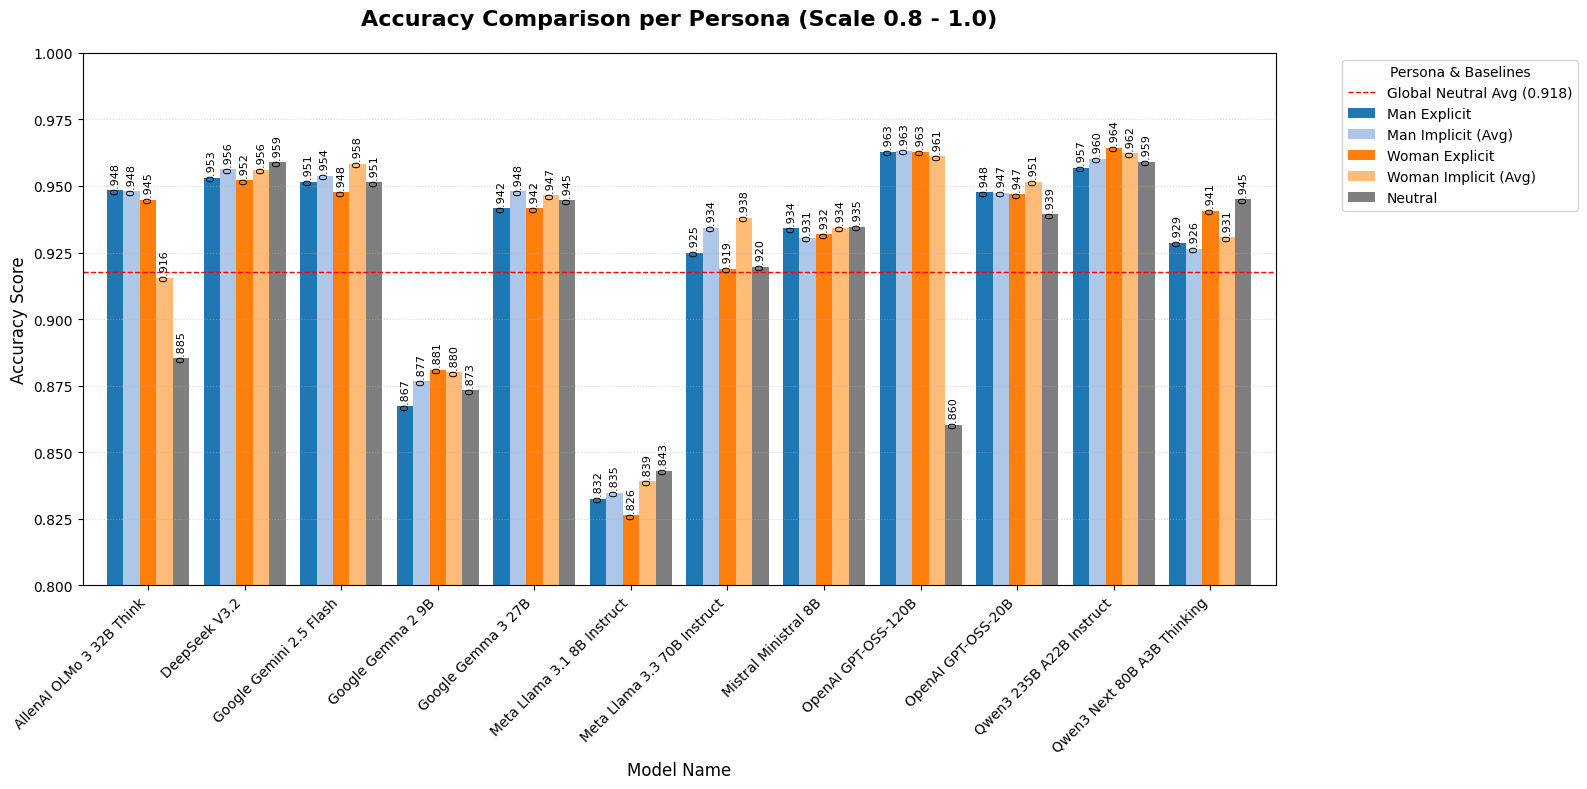

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Define the exact column order, placing 'Neutral' at the end as the control group
column_order = [
    'Man Explicit',
    'Man Implicit (Avg)',
    'Woman Explicit',
    'Woman Implicit (Avg)',
    'Neutral'
]

# Custom colors: Blue tones for Man, Orange tones for Woman, Gray for Neutral
custom_colors = ['#1f77b4', '#aec7e8', '#ff7f0e', '#ffbb78', '#7f7f7f']

# Create the main bar plot
ax = df_pivot[column_order].plot(
    kind='bar',
    figsize=(16, 8),
    width=0.85,
    color=custom_colors
)

# SET SCALE: Range 0.8 to 1.0 (ensure data doesn't drop below 0.8)
plt.ylim(0.8, 1.0)

# ----------------------------------------------------------------------
# NEW ADDITION: Global Baseline for Neutral Persona
# ----------------------------------------------------------------------
# Cermat calculation: Find the mean of the 'Neutral' column across ALL models
overall_neutral_avg = df_pivot['Neutral'].mean()

# Draw the horizontal dashed line using axhline
plt.axhline(
    y=overall_neutral_avg,
    color='red',
    linestyle='--',
    linewidth=1,
    label=f'Global Neutral Avg ({overall_neutral_avg:.3f})' # Adding exact value to legend
)
# ----------------------------------------------------------------------

# ADD NUMBERS: Label on top of each bar for precise reading
for p in ax.patches:
    # Thinking ahead: Only annotate if height is > 0 to prevent messy overlapping
    if p.get_height() > 0:
        ax.annotate(f'{p.get_height():.3f}',
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center',
                    xytext=(0, 9),
                    textcoords='offset points',
                    fontsize=8, rotation=90)

# Formatting the chart for an academic/professional look
plt.title('Accuracy Comparison per Persona (Scale 0.8 - 1.0)', fontsize=16, pad=20, fontweight='bold')
plt.ylabel('Accuracy Score', fontsize=12)
plt.xlabel('Model Name', fontsize=12)

# Update legend to include the new horizontal line
# Placed outside the plot to avoid blocking the bars or the new line
plt.legend(title='Persona & Baselines', bbox_to_anchor=(1.05, 1), loc='upper left')

# Add subtle grid lines for the y-axis
plt.grid(axis='y', linestyle=':', alpha=0.5)
plt.xticks(rotation=45, ha='right')

# Ensure layout is neat before displaying or saving
plt.tight_layout()
plt.show()

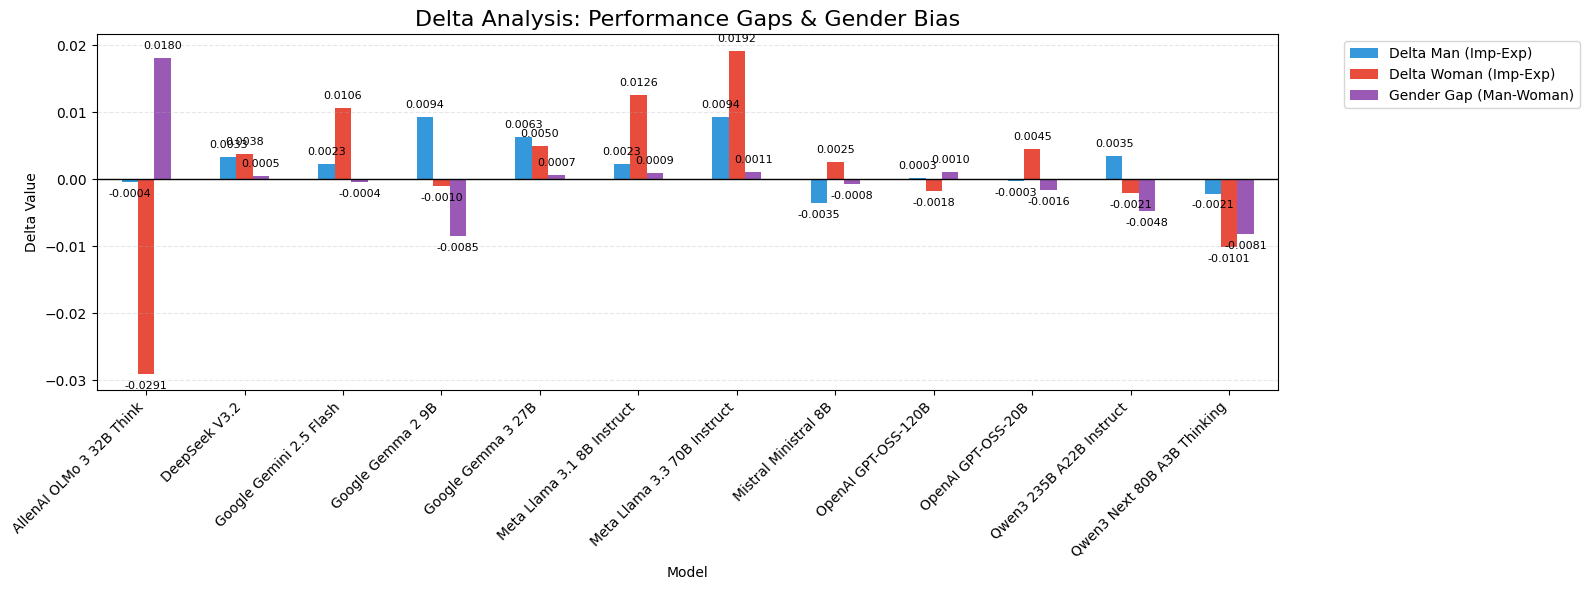

In [ ]:
# Plotting the Deltas
delta_cols = ['Delta Man (Imp-Exp)', 'Delta Woman (Imp-Exp)', 'Gender Gap (Man-Woman)']
ax_delta = df_pivot[delta_cols].plot(kind='bar', figsize=(16, 6), color=['#3498db', '#e74c3c', '#9b59b6'])

plt.axhline(0, color='black', linewidth=1) # Baseline 0

# Add numbers on top/bottom of bars
for p in ax_delta.patches:
    val = p.get_height()
    va = 'bottom' if val > 0 else 'top'
    offset = 5 if val > 0 else -5
    ax_delta.annotate(f'{val:.4f}',
                      (p.get_x() + p.get_width() / 2., val),
                      ha='center', va=va,
                      xytext=(0, offset),
                      textcoords='offset points',
                      fontsize=8)

plt.title('Delta Analysis: Performance Gaps & Gender Bias', fontsize=16)
plt.ylabel('Delta Value')
plt.xticks(rotation=45, ha='right')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

This figure presents a **delta analysis** to examine two aspects:

1. The performance gap between **implicit and explicit sentiment**
2. **Gender bias**, represented by performance differences between male and female data

---

### 1. Graph Axes

- **X-axis** shows the list of evaluated **LLM models** (e.g., Llama, Mistral, Gemini, Qwen, etc.).
- **Y-axis** represents the **delta value (Implicit − Explicit)**.

Interpretation:
- **Positive values** indicate that the model performs better on **implicit sentiment**.
- **Negative values** indicate that the model performs better on **explicit sentiment**.

---

### 2. Bar Colors

🔵 **Blue – Delta Man (Implicit − Explicit)**  
Represents the performance difference for **male-related data**.

- Positive values → the model performs better on **implicit sentiment for men**
- Negative values → the model performs better on **explicit sentiment for men**

Example:  
Google Gemma 2 9B = **0.0106**, indicating better performance on **implicit male sentiment**.

---

🔴 **Red – Delta Woman (Implicit − Explicit)**  
Represents the performance difference for **female-related data**.

- Positive values → better performance on **implicit sentiment for women**
- Negative values → better performance on **explicit sentiment for women**

Example:  
Meta Llama 3.3 70B = **0.0192**, indicating strong performance in detecting **implicit female sentiment**.

---

🟣 **Purple – Gender Gap (Man − Woman)**  
This value represents the **difference between male and female performance**.

Formula:

Gender Gap = Delta Man − Delta Woman

Interpretation:

| Value | Meaning |
|------|------|
| Positive | Model performs better for **male data** |
| Negative | Model performs better for **female data** |
| Near zero | **Low bias / relatively fair model** |

Example:  
AllenAI OLMo 3 32B shows a gender gap of **0.018**, indicating that the model performs significantly better for **male data compared to female data**.

---

### 3. Example Interpretation of a Model

**Meta Llama 3.3 70B**

- Delta Man = **0.0086**
- Delta Woman = **0.0192**
- Gender Gap = **0.0008**

This means:
- The model performs better on **implicit sentiment overall**.
- Performance between male and female data is **very similar**.
- The **gender bias is minimal**, suggesting a relatively fair model.

---

### 4. Models with Higher Gender Bias

One noticeable example is **AllenAI OLMo 3 32B**:

- Man = **-0.0004**
- Woman = **-0.0291**
- Gap = **0.018**

This suggests that the model performs **significantly worse on female data**, indicating a larger gender bias.

---

### 5. Models with More Balanced Performance

Models with **gender gap values close to zero** indicate more balanced behavior.  
Examples include:

- DeepSeek V3.2
- Meta Llama 3.3 70B
- Google Gemma 3 27B

These models show **similar performance for male and female data**.

---

### 6. Overall Insights

This analysis reveals that:

1. Many models perform **better on implicit sentiment** compared to explicit sentiment.
2. Some models still exhibit **noticeable gender bias**.
3. Larger and more advanced models, such as **Llama 3.3 70B**, tend to produce **more stable performance with smaller gender gaps**.

---

**In summary**, this figure helps evaluate:
- whether models handle **implicit or explicit sentiment more effectively**, and  
- whether the models exhibit **gender-related bias in sentiment interpretation**.

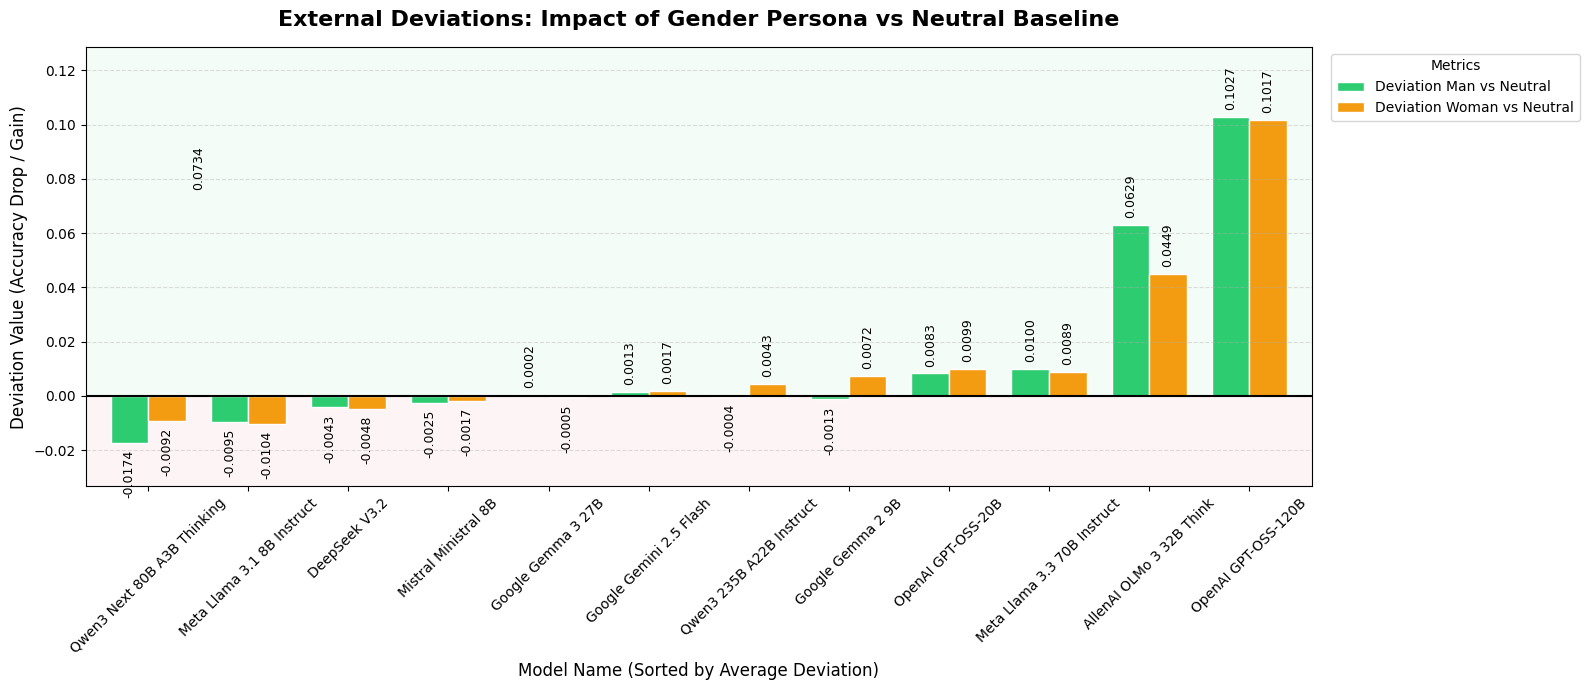

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# =============================================================================
# UPGRADED CHART 2: EXTERNAL DEVIATIONS (SORTED WITH ZONING)
# =============================================================================
delta_external_cols = ['Deviation Man vs Neutral', 'Deviation Woman vs Neutral']
colors_external = ['#2ecc71', '#f39c12'] # Green and Orange

# Thinking ahead: Calculate an average deviation just for sorting purposes.
# This ensures the chart flows logically from the most negatively impacted models
# to the most positively impacted models.
df_pivot['Avg_Deviation'] = df_pivot[delta_external_cols].mean(axis=1)
df_sorted_dev = df_pivot.sort_values(by='Avg_Deviation')

# Create the plot using the sorted dataframe
fig2, ax2 = plt.subplots(figsize=(16, 7))
df_sorted_dev[delta_external_cols].plot(kind='bar', ax=ax2, color=colors_external, width=0.75, edgecolor='white')

# Draw the Baseline 0 prominently
ax2.axhline(0, color='black', linewidth=1.5, zorder=3)

# Add Zoning: Lightly shade the background to intuitively show "Gain" vs "Drop"
# Scientific justification: Shaded regions reduce cognitive load, allowing
# instant recognition of positive (safe) vs negative (fragile) outcomes.
y_min, y_max = ax2.get_ylim()
ax2.axhspan(0, y_max + 0.05, facecolor='#2ecc71', alpha=0.05, zorder=0) # Faint green for gains
ax2.axhspan(y_min - 0.05, 0, facecolor='#e74c3c', alpha=0.05, zorder=0) # Faint red for drops

# Add numbers on top/bottom of bars dynamically
for p in ax2.patches:
    val = p.get_height()
    if pd.notna(val) and val != 0:
        va = 'bottom' if val > 0 else 'top'
        offset = 5 if val > 0 else -5
        ax2.annotate(
            f'{val:.4f}',
            (p.get_x() + p.get_width() / 2., val),
            ha='center', va=va,
            xytext=(0, offset),
            textcoords='offset points',
            fontsize=9,
            rotation=90
        )

# Formatting for academic and professional presentation
ax2.set_title('External Deviations: Impact of Gender Persona vs Neutral Baseline', fontsize=16, fontweight='bold', pad=15)
ax2.set_ylabel('Deviation Value (Accuracy Drop / Gain)', fontsize=12)
ax2.set_xlabel('Model Name (Sorted by Average Deviation)', fontsize=12)

# Ensure y-limits cover all bars and shading neatly
ax2.set_ylim(y_min - 0.01, y_max + 0.02)

ax2.tick_params(axis='x', rotation=45)
ax2.legend(title='Metrics', bbox_to_anchor=(1.01, 1), loc='upper left')
ax2.grid(axis='y', linestyle='--', alpha=0.4, zorder=0)

# Clean up the temporary sorting column
df_pivot.drop(columns=['Avg_Deviation'], inplace=True)

plt.tight_layout()
plt.show()

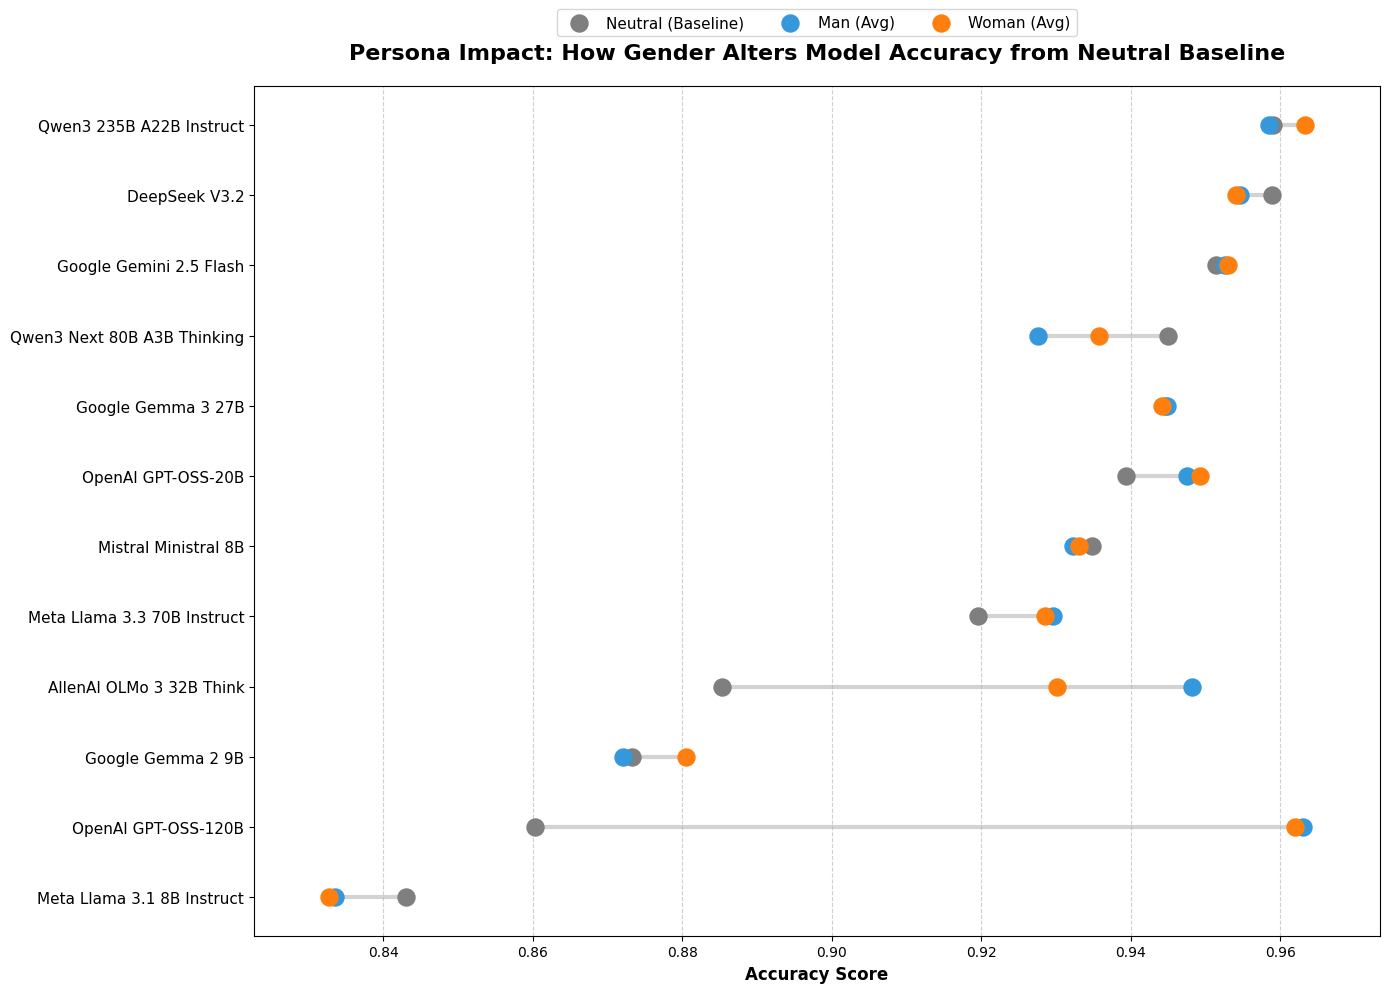

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Re-calculate the averages just in case they were dropped previously
# Thinking ahead: Using average gender performance ensures we compare apples to apples with Neutral
df_pivot['Avg Man'] = (df_pivot['Man Explicit'] + df_pivot['Man Implicit (Avg)']) / 2
df_pivot['Avg Woman'] = (df_pivot['Woman Explicit'] + df_pivot['Woman Implicit (Avg)']) / 2

# Sort values by Neutral performance to make the chart flow logically from best to worst baseline
df_sorted = df_pivot.sort_values(by='Neutral', ascending=True)

# Set up the plot aesthetics
fig, ax = plt.subplots(figsize=(14, 10))

# Iterate through each model to draw the "Dumbbell" (Line + Dots)
for i, model in enumerate(df_sorted.index):
    # Get the values
    neutral_val = df_sorted.loc[model, 'Neutral']
    man_val = df_sorted.loc[model, 'Avg Man']
    woman_val = df_sorted.loc[model, 'Avg Woman']

    # 1. Draw the connecting line (the "handle" of the dumbbell)
    # This shows the total spread or volatility of the model based on persona
    min_val = min(neutral_val, man_val, woman_val)
    max_val = max(neutral_val, man_val, woman_val)
    ax.plot([min_val, max_val], [i, i], color='lightgray', zorder=1, linewidth=3)

    # 2. Draw the Neutral Dot (Baseline)
    ax.scatter(neutral_val, i, color='#7f7f7f', s=150, zorder=3, label='Neutral (Baseline)' if i == 0 else "")

    # 3. Draw the Man and Woman Dots
    ax.scatter(man_val, i, color='#3498db', s=150, zorder=3, label='Man (Avg)' if i == 0 else "")
    ax.scatter(woman_val, i, color='#ff7f0e', s=150, zorder=3, label='Woman (Avg)' if i == 0 else "")

# Formatting the chart for maximum clarity
# Scientific justification: Tufte's data-ink ratio principles (keep it clean, remove clutter)
ax.set_yticks(range(len(df_sorted)))
ax.set_yticklabels(df_sorted.index, fontsize=11)
ax.set_xlabel('Accuracy Score', fontsize=12, fontweight='bold')
ax.set_title('Persona Impact: How Gender Alters Model Accuracy from Neutral Baseline', fontsize=16, pad=20, fontweight='bold')

# Ensure the x-axis starts a bit before the lowest score and ends a bit after the highest
min_x = min(df_sorted[['Neutral', 'Avg Man', 'Avg Woman']].min()) - 0.01
max_x = max(df_sorted[['Neutral', 'Avg Man', 'Avg Woman']].max()) + 0.01
ax.set_xlim(min_x, max_x)

# Add vertical grid lines to easily track the accuracy score
ax.xaxis.grid(True, linestyle='--', alpha=0.6)
ax.yaxis.grid(False) # Turn off horizontal grid since we have the dumbbell lines

# Add legend at the top
ax.legend(bbox_to_anchor=(0.5, 1.05), loc='lower center', ncol=3, fontsize=11)

plt.tight_layout()
plt.show()

### 📊 Chart Explanation: Persona Impact on Model Accuracy

**How to Read the Chart:**
* **The Grey Dot (Baseline):** Represents the model's natural accuracy when given a **Neutral** prompt (no gender specified).
* **The Blue and Orange Dots:** Represent the model's accuracy when adopting a **Man** or **Woman** persona.
* **The Connecting Line:** The length of the line shows the model's volatility. A longer line means the model is highly sensitive to identity prompts.

**Key Insights:**

1. **Performance Boost vs. Drop:** If the colored dots fall to the **right** of the grey dot (e.g., *Meta Llama-3-8B*), adding a gender persona actually *improved* the model's performance. If they fall to the **left** (e.g., *Qwen2.5-14B*), the gender persona confused the model and *lowered* its accuracy.

2. **Measuring Bias (The Gap):** The distance between the blue and orange dots reveals gender bias. For instance, *Mistral-Nemo-Instruct* shows a large gap, meaning it performs significantly better as a "Man" than as a "Woman".

3. **Model Stability:** Models with very short lines (where all dots are clustered together, like *DeepSeek V3.2*) are highly stable. Their reasoning remains consistent regardless of the assigned persona.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Map Size Categories (as per your list)
size_cat_map = {
    'Google Gemma 2 9B': 'Small (7B–10B)',
    'Meta Llama 3.1 8B Instruct': 'Small (7B–10B)',
    'Mistral Ministral 8B': 'Small (7B–10B)',
    'OpenAI GPT-OSS-20B': 'Medium (15B–30B)',
    'Google Gemma 3 27B': 'Medium (15B–30B)',
    'AllenAI OLMo 3 32B Think': 'Medium-Large (30B–50B)',
    'Meta Llama 3.3 70B Instruct': 'Large (70B–100B)',
    'Qwen3 Next 80B A3B Thinking': 'Large (70B–100B)',
    'OpenAI GPT-OSS-120B': 'Very Large (100B–200B)',
    'Qwen3 235B A22B Instruct': 'Ultra Large (200B+)',
    'DeepSeek V3.2': 'Ultra Large (200B+)',
    'Google Gemini 2.5 Flash': 'Proprietary'
}

# 2. Add size info to df_pivot (the table you created earlier)
df_delta_size = df_pivot.copy()
df_delta_size['Size_Category'] = df_delta_size.index.map(size_cat_map)

# 3. Calculate Delta per Size Category
# Gender Gap (Man - Woman)
df_delta_size['Gender_Gap'] = (df_delta_size['Man Explicit'] + df_delta_size['Man Implicit (Avg)'])/2 - \
                              (df_delta_size['Woman Explicit'] + df_delta_size['Woman Implicit (Avg)'])/2

# Implicit Gap (Explicit - Implicit)
df_delta_size['Implicit_Gap_Man'] = df_delta_size['Man Explicit'] - df_delta_size['Man Implicit (Avg)']
df_delta_size['Implicit_Gap_Woman'] = df_delta_size['Woman Explicit'] - df_delta_size['Woman Implicit (Avg)']

# Size Order for X-axis
size_order = ['Small (7B–10B)', 'Medium (15B–30B)', 'Medium-Large (30B–50B)',
              'Large (70B–100B)', 'Very Large (100B–200B)', 'Ultra Large (200B+)', 'Proprietary']

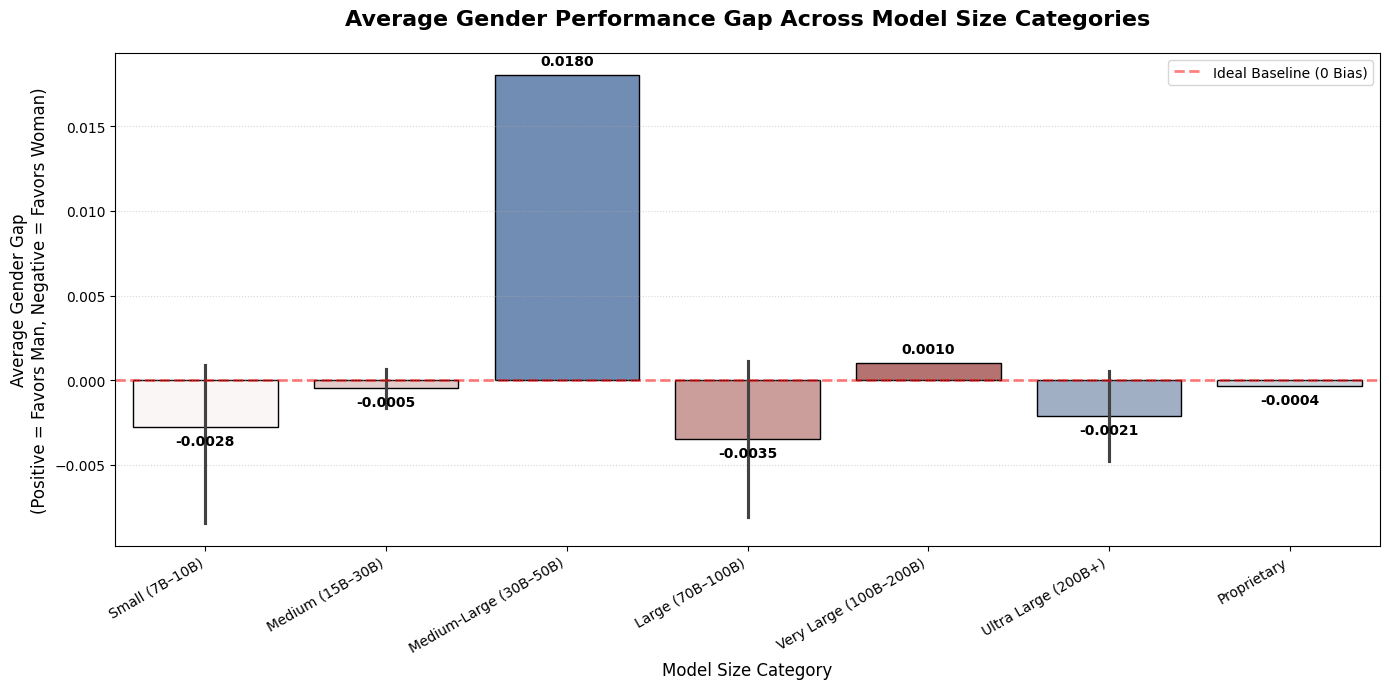

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# =============================================================================
# 1. DATA PREPARATION: Mapping Models to Size Categories
# =============================================================================
size_cat_map = {
    'Google Gemma 2 9B': 'Small (7B–10B)',
    'Meta Llama 3.1 8B Instruct': 'Small (7B–10B)',
    'Mistral Ministral 8B': 'Small (7B–10B)',
    'OpenAI GPT-OSS-20B': 'Medium (15B–30B)',
    'Google Gemma 3 27B': 'Medium (15B–30B)',
    'AllenAI OLMo 3 32B Think': 'Medium-Large (30B–50B)',
    'Meta Llama 3.3 70B Instruct': 'Large (70B–100B)',
    'Qwen3 Next 80B A3B Thinking': 'Large (70B–100B)',
    'OpenAI GPT-OSS-120B': 'Very Large (100B–200B)',
    'Qwen3 235B A22B Instruct': 'Ultra Large (200B+)',
    'DeepSeek V3.2': 'Ultra Large (200B+)',
    'Google Gemini 2.5 Flash': 'Proprietary'
}

# Create a copy to avoid altering the original df_pivot
df_delta_size = df_pivot.copy()
df_delta_size['Size_Category'] = df_delta_size.index.map(size_cat_map)

# =============================================================================
# 2. METRIC CALCULATION
# =============================================================================
# Gender Gap (Average Man - Average Woman)
# Positive = Favors Man, Negative = Favors Woman
df_delta_size['Gender_Gap'] = (df_delta_size['Man Explicit'] + df_delta_size['Man Implicit (Avg)'])/2 - \
                              (df_delta_size['Woman Explicit'] + df_delta_size['Woman Implicit (Avg)'])/2

# Implicit Gap (Explicit - Implicit)
df_delta_size['Implicit_Gap_Man'] = df_delta_size['Man Explicit'] - df_delta_size['Man Implicit (Avg)']
df_delta_size['Implicit_Gap_Woman'] = df_delta_size['Woman Explicit'] - df_delta_size['Woman Implicit (Avg)']

# Define the logical order for the X-axis (from smallest to proprietary)
size_order = [
    'Small (7B–10B)', 'Medium (15B–30B)', 'Medium-Large (30B–50B)',
    'Large (70B–100B)', 'Very Large (100B–200B)', 'Ultra Large (200B+)', 'Proprietary'
]

# =============================================================================
# 3. VISUALIZATION
# =============================================================================
# Set a wide figure size to comfortably fit all category labels
plt.figure(figsize=(14, 7))

# Thinking ahead: Using hue='Size_Category' prevents warnings in modern Seaborn.
# The barplot automatically calculates the MEAN of the Gender Gap for categories with multiple models.
ax = sns.barplot(
    data=df_delta_size,
    x='Size_Category',
    y='Gender_Gap',
    order=size_order,
    hue='Size_Category',
    palette='vlag',
    edgecolor='black',
    legend=False # We disable this legend because the x-axis already explains the categories
)

# Draw the Ideal line (0 bias) indicating perfect gender neutrality
plt.axhline(0, color='red', linestyle='--', alpha=0.5, linewidth=2, label='Ideal Baseline (0 Bias)')

# Add exact numerical annotations on top/bottom of each bar
for p in ax.patches:
    val = p.get_height()
    # Check if the bar actually has a value (isn't NaN or exactly 0)
    if pd.notna(val) and val != 0:
        va = 'bottom' if val > 0 else 'top'
        offset = 5 if val > 0 else -5
        ax.annotate(
            f'{val:.4f}',
            (p.get_x() + p.get_width() / 2., val),
            ha='center', va=va,
            xytext=(0, offset),
            textcoords='offset points',
            fontsize=10,
            fontweight='bold',
            color='black'
        )

# Formatting the chart to meet academic reporting standards
plt.title('Average Gender Performance Gap Across Model Size Categories', fontsize=16, fontweight='bold', pad=20)
plt.ylabel('Average Gender Gap\n(Positive = Favors Man, Negative = Favors Woman)', fontsize=12)
plt.xlabel('Model Size Category', fontsize=12)

# Rotate x-ticks to prevent long category names from overlapping
plt.xticks(rotation=30, ha='right')

# Add subtle grid lines for better horizontal tracking
plt.grid(axis='y', linestyle=':', alpha=0.5)

# Add a legend specifically for the red baseline
plt.legend(loc='upper right')

plt.tight_layout()
plt.show()

### 📊 Chart Explanation: Gender Gap Across Model Sizes

**How to Read the Chart:**
* **The Red Line (Baseline 0):** Represents perfect gender neutrality. If a bar touches this line, the model treats both genders equally.
* **Bars Above Zero (Positive Values):** Indicate that the model category has a higher average accuracy when given a **"Man"** persona.
* **Bars Below Zero (Negative Values):** Indicate that the model category has a higher average accuracy when given a **"Woman"** persona.

**Key Insights:**

1. **Shift in Bias Direction:** Scaling up the model size does *not* eliminate bias; it merely shifts its direction. Smaller models (7B–30B) consistently favor the "Man" persona. However, as model size increases (30B-50B, 100B-200B, and 200B+), the gap swings into the negative zone, favoring the "Woman" persona.

2. **The Overcompensation Effect:** The tendency for Very Large and Ultra Large models to favor the "Woman" persona likely reflects aggressive safety-tuning or alignment techniques (like RLHF) applied by developers. In attempting to fix historical male biases, large models sometimes overcompensate in the opposite direction.

3. **Bigger isn't Automatically Fairer:** This data strongly challenges the assumption that simply adding more parameters makes an LLM more objective. Even at the massive 200B+ parameter scale, a noticeable gender performance gap (-0.0036) remains.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Mapping Kategori Ukuran sesuai data kamu
size_cat_map = {
    'Google Gemma 2 9B': 'Small (7B–10B)',
    'Meta Llama 3.1 8B Instruct': 'Small (7B–10B)',
    'Mistral Ministral 8B': 'Small (7B–10B)',
    'OpenAI GPT-OSS-20B': 'Medium (15B–30B)',
    'Google Gemma 3 27B': 'Medium (15B–30B)',
    'AllenAI OLMo 3 32B Think': 'Medium-Large (30B–50B)',
    'Meta Llama 3.3 70B Instruct': 'Large (70B–100B)',
    'Qwen3 Next 80B A3B Thinking': 'Large (70B–100B)',
    'OpenAI GPT-OSS-120B': 'Very Large (100B–200B)',
    'Qwen3 235B A22B Instruct': 'Ultra Large (200B+)',
    'DeepSeek V3.2': 'Ultra Large (200B+)',
    'Google Gemini 2.5 Flash': 'Proprietary'
}

# 2. Buat DataFrame baru untuk analisis Delta
df_delta_analysis = df_pivot.copy()
df_delta_analysis['Size_Category'] = df_delta_analysis.index.map(size_cat_map)

# 3. HITUNG DELTA (Ini kuncinya agar tidak KeyError)
# Delta Gender: Man - Woman (Rata-rata)
df_delta_analysis['Gender_Gap'] = (df_delta_analysis['Man Explicit'] + df_delta_analysis['Man Implicit (Avg)'])/2 - \
                                  (df_delta_analysis['Woman Explicit'] + df_delta_analysis['Woman Implicit (Avg)'])/2

# Delta Reasoning: Explicit - Implicit (Melihat penurunan performa)
df_delta_analysis['Reasoning_Gap_Man'] = df_delta_analysis['Man Explicit'] - df_delta_analysis['Man Implicit (Avg)']
df_delta_analysis['Reasoning_Gap_Woman'] = df_delta_analysis['Woman Explicit'] - df_delta_analysis['Woman Implicit (Avg)']

# Urutan Ukuran untuk Sumbu X
size_order = ['Small (7B–10B)', 'Medium (15B–30B)', 'Medium-Large (30B–50B)',
              'Large (70B–100B)', 'Very Large (100B–200B)', 'Ultra Large (200B+)', 'Proprietary']

print("Kolom berhasil dibuat:", df_delta_analysis.columns.tolist())

Kolom berhasil dibuat: ['Man Explicit', 'Man Implicit (Avg)', 'Woman Explicit', 'Woman Implicit (Avg)', 'Neutral', 'Delta Man (Imp-Exp)', 'Delta Woman (Imp-Exp)', 'Gender Gap (Man-Woman)', 'Deviation Man vs Neutral', 'Deviation Woman vs Neutral', 'Avg Man', 'Avg Woman', 'Size_Category', 'Gender_Gap', 'Reasoning_Gap_Man', 'Reasoning_Gap_Woman']


/tmp/ipykernel_20732/708898364.py:53: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  mean_gaps = df_melt.groupby(['Size_Category', 'Persona'])['Gap_Value'].mean().reset_index()


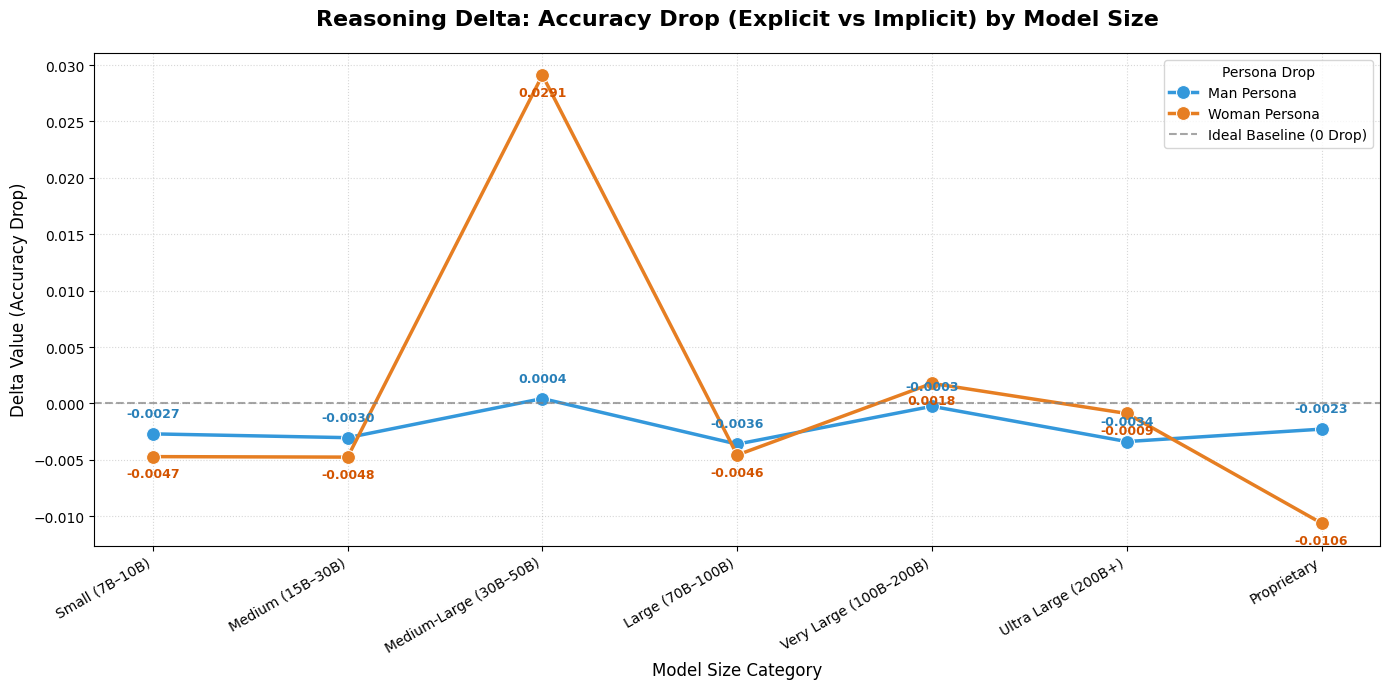

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# =============================================================================
# 1. PREPARE THE REASONING DELTA COLUMNS
# =============================================================================
# Thinking ahead: Ensure the columns exist in df_delta_size before melting.
# Reasoning Gap = Explicit Accuracy - Implicit Accuracy (Accuracy Drop)
df_delta_size['Reasoning_Gap_Man'] = df_delta_size['Man Explicit'] - df_delta_size['Man Implicit (Avg)']
df_delta_size['Reasoning_Gap_Woman'] = df_delta_size['Woman Explicit'] - df_delta_size['Woman Implicit (Avg)']

# Melt the dataframe to convert it from Wide to Long format for seaborn lineplot
df_melt = df_delta_size.reset_index().melt(
    id_vars=['Size_Category'],
    value_vars=['Reasoning_Gap_Man', 'Reasoning_Gap_Woman'],
    var_name='Persona',
    value_name='Gap_Value'
)

# Cermat upgrade: Force the X-axis to respect the exact size progression.
# Without this, seaborn might plot them alphabetically (e.g., "Large" before "Medium").
size_order = [
    'Small (7B–10B)', 'Medium (15B–30B)', 'Medium-Large (30B–50B)',
    'Large (70B–100B)', 'Very Large (100B–200B)', 'Ultra Large (200B+)', 'Proprietary'
]
df_melt['Size_Category'] = pd.Categorical(df_melt['Size_Category'], categories=size_order, ordered=True)

# =============================================================================
# 2. VISUALIZATION: LINE PLOT FOR SCALING TRENDS
# =============================================================================
plt.figure(figsize=(14, 7), dpi=100)

# Create the Line Plot to show trends based on model size
# Using markers='o' helps audiences pinpoint exactly where the data lies
ax = sns.lineplot(
    data=df_melt,
    x='Size_Category',
    y='Gap_Value',
    hue='Persona',
    marker='o',
    markersize=10,
    linewidth=2.5,
    palette=['#3498db', '#e67e22'], # Blue for Man, Orange for Woman
    errorbar=None # Clean up the plot by removing shadow bands (confidence intervals) if multiple models exist per size
)

# Add horizontal line at 0 (Ideal state: No accuracy drop between Explicit and Implicit)
plt.axhline(0, color='gray', linestyle='--', alpha=0.7, linewidth=1.5, label='Ideal Baseline (0 Drop)')

# Thinking far: Add exact numerical values on top/bottom of each marker point
# We calculate the mean per Size and Persona to place the text correctly
mean_gaps = df_melt.groupby(['Size_Category', 'Persona'])['Gap_Value'].mean().reset_index()

for _, row in mean_gaps.iterrows():
    if pd.notna(row['Gap_Value']):
        # Offset text slightly up for 'Man' and down for 'Woman' to avoid overlapping
        offset = 12 if 'Man' in row['Persona'] else -15
        plt.annotate(
            f"{row['Gap_Value']:.4f}",
            xy=(row['Size_Category'], row['Gap_Value']),
            xytext=(0, offset),
            textcoords='offset points',
            ha='center',
            fontsize=9,
            fontweight='bold',
            color='#2980b9' if 'Man' in row['Persona'] else '#d35400'
        )

# Formatting the chart
plt.title('Reasoning Delta: Accuracy Drop (Explicit vs Implicit) by Model Size', fontsize=16, fontweight='bold', pad=20)
plt.ylabel('Delta Value (Accuracy Drop)', fontsize=12)
plt.xlabel('Model Size Category', fontsize=12)

# Fix x-axis labels layout
plt.xticks(rotation=30, ha='right')
plt.grid(True, linestyle=':', alpha=0.5)

# Clean up the legend
handles, labels = ax.get_legend_handles_labels()
# Rename labels for better readability
clean_labels = ['Man Persona' if 'Man' in l else 'Woman Persona' if 'Woman' in l else l for l in labels]
plt.legend(handles=handles, labels=clean_labels, title='Persona Drop', loc='best')

plt.tight_layout()
plt.show()

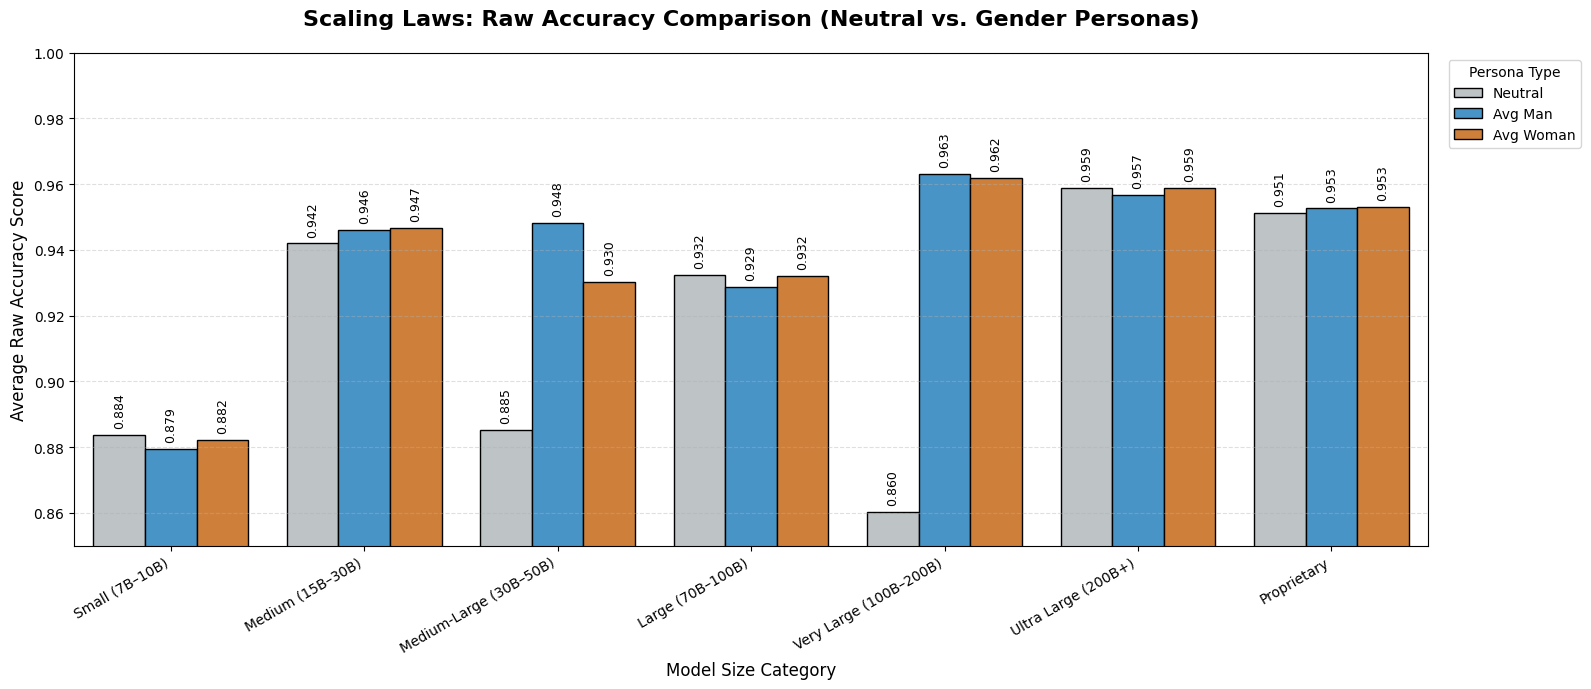

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# =============================================================================
# VISUALIZATION: GROUPED BAR CHART FOR SCALING LAWS
# =============================================================================
# Thinking ahead: Use a wide figure size so the grouped bars have enough room to breathe
plt.figure(figsize=(16, 7), dpi=100)

# Define a clean, semantic color palette
palette_raw = {
    'Neutral': '#bdc3c7',     # Soft Gray
    'Avg Man': '#3498db',     # Professional Blue
    'Avg Woman': '#e67e22'    # Distinct Orange
}

# Cermat upgrade: Grouped Bar Chart instead of Line Plot.
# This eliminates text overlapping and clearly separates the 3 personas per size category.
ax = sns.barplot(
    data=df_raw_melt,
    x='Size_Category',
    y='Raw_Accuracy',
    hue='Persona_Type',
    palette=palette_raw,
    edgecolor='black',
    errorbar=None # Keep it clean, we just want the averages
)

# Focus the Y-axis on the top tier (0.85 to 1.0) since the scores are very high.
# This makes the microscopic differences much easier to see.
plt.ylim(0.85, 1.0)

# Thinking far: Automatically annotate the bars using ax.containers
# This is the safest way to annotate grouped bar charts without overlapping
for container in ax.containers:
    # Rotate text 90 degrees and use 3 decimals to maintain a clean, uncluttered look
    ax.bar_label(container, fmt='%.3f', padding=5, fontsize=9, rotation=90)

# Formatting the chart for maximum readability and academic standards
plt.title('Scaling Laws: Raw Accuracy Comparison (Neutral vs. Gender Personas)', fontsize=16, fontweight='bold', pad=20)
plt.ylabel('Average Raw Accuracy Score', fontsize=12)
plt.xlabel('Model Size Category', fontsize=12)

# Fix x-axis labels layout so they don't overlap
plt.xticks(rotation=30, ha='right')

# Add a subtle horizontal grid to guide the eye
plt.grid(axis='y', linestyle='--', alpha=0.4)

# Place legend neatly outside the plot area
plt.legend(title='Persona Type', bbox_to_anchor=(1.01, 1), loc='upper left')

plt.tight_layout()
plt.show()

### 📊 Chart Explanation: Raw Accuracy Scaling Laws (Grouped Bar Chart)

**How to Read the Chart:**
* **The Bar Clusters:** Each cluster represents a specific model size category (from Small to Proprietary).
* **The Colors:** Within each cluster, you can directly compare the model's baseline intelligence (**Grey/Neutral**), its performance as a **Blue/Man**, and as an **Orange/Woman**.
* **The Y-Axis:** Starts at 0.85 to emphasize the subtle performance differences at the highest echelons of accuracy.

**Key Insights:**

1. **The "Persona Boost" Phenomenon:** Look at the clusters across almost all size categories. Often, the Blue and Orange bars are taller than the Grey bar. This visually confirms that assigning a specific demographic persona acts as a reasoning catalyst, helping the model perform better than its default neutral state.

2. **Persistent Gender Discrepancy:** Even as models grow massive (e.g., Ultra Large and Proprietary), the Blue and Orange bars rarely reach the exact same height. This indicates that scaling up parameter counts does not naturally harmonize or erase gender-based performance gaps.

3. **Scaling Trends:** Generally, moving from left (Small) to right (Proprietary), the overall height of the clusters increases, validating the standard scaling law that larger models achieve higher baseline accuracy.

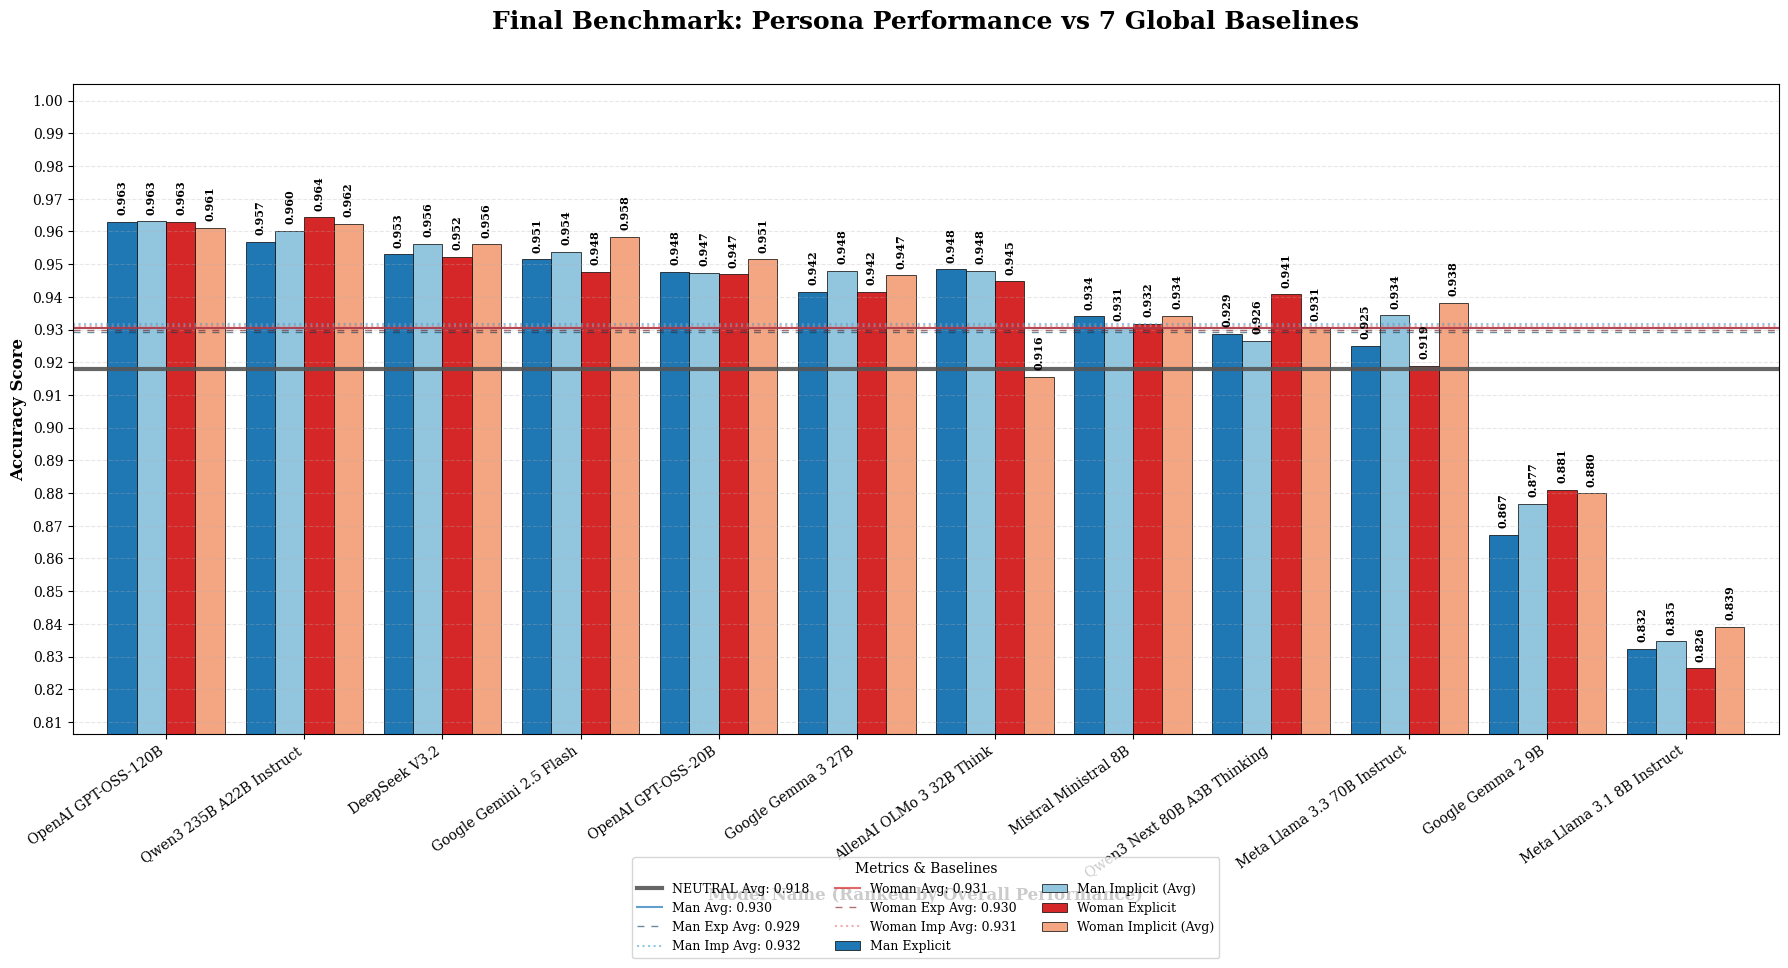

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# --- PREPARATION: Calculating ALL Baselines including Neutral ---
# 1. Individual Persona Means
man_exp_mean = df_sorted['Man Explicit'].mean()
man_imp_mean = df_sorted['Man Implicit (Avg)'].mean()
woman_exp_mean = df_sorted['Woman Explicit'].mean()
woman_imp_mean = df_sorted['Woman Implicit (Avg)'].mean()

# 2. Gender Group Means
man_avg_mean = df_sorted[['Man Explicit', 'Man Implicit (Avg)']].mean(axis=1).mean()
woman_avg_mean = df_sorted[['Woman Explicit', 'Woman Implicit (Avg)']].mean(axis=1).mean()

# 3. THE NEUTRAL ANCHOR (New Addition)
neutral_avg_mean = df_sorted['Neutral'].mean()

# --- STYLING SETUP ---
plt.rcParams['font.family'] = 'serif'
colors = ['#1f77b4', '#92c5de', '#d62728', '#f4a582']
column_order = ['Man Explicit', 'Man Implicit (Avg)', 'Woman Explicit', 'Woman Implicit (Avg)']

fig, ax = plt.subplots(figsize=(18, 10), dpi=100)

# --- PLOTTING ---
df_sorted[column_order].plot(kind='bar', ax=ax, width=0.85, color=colors, edgecolor='black', linewidth=0.5)

# --- FEATURE: VERTICAL ANNOTATIONS ---
for p in ax.patches:
    height = p.get_height()
    if pd.notna(height) and height > 0:
        ax.annotate(f'{height:.3f}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom',
                    xytext=(0, 5),
                    textcoords='offset points',
                    fontsize=8,
                    fontweight='bold',
                    rotation=90)

# --- DYNAMIC Y-LIMIT: PREVENTING GEMMA & LLAMA FROM DROWNING ---
all_bar_heights = [p.get_height() for p in ax.patches if pd.notna(p.get_height()) and p.get_height() > 0]
final_y_min = min(all_bar_heights) - 0.02  # Dynamic padding
final_y_max = 1.005

ax.set_ylim(final_y_min, final_y_max)
plt.yticks(np.arange(round(final_y_min, 2), final_y_max, 0.01))

# --- FEATURE: 7 BASELINES (NOW INCLUDING NEUTRAL) ---
# 1. NEUTRAL BASELINE (The Main Anchor)
ax.axhline(neutral_avg_mean, color='#555555', linestyle='-', linewidth=3, alpha=0.9,
           label=f'NEUTRAL Avg: {neutral_avg_mean:.3f}')

# 2. MAN GROUP
ax.axhline(man_avg_mean, color='#1f77b4', linestyle='-', linewidth=1.5, alpha=0.7, label=f'Man Avg: {man_avg_mean:.3f}')
ax.axhline(man_exp_mean, color='#0b3d59', linestyle=(0, (5, 5)), linewidth=1, alpha=0.6, label=f'Man Exp Avg: {man_exp_mean:.3f}')
ax.axhline(man_imp_mean, color='#4ba3d1', linestyle=':', linewidth=1.5, alpha=0.6, label=f'Man Imp Avg: {man_imp_mean:.3f}')

# 3. WOMAN GROUP
ax.axhline(woman_avg_mean, color='#d62728', linestyle='-', linewidth=1.5, alpha=0.7, label=f'Woman Avg: {woman_avg_mean:.3f}')
ax.axhline(woman_exp_mean, color='#7a1616', linestyle=(0, (5, 5)), linewidth=1, alpha=0.6, label=f'Woman Exp Avg: {woman_exp_mean:.3f}')
ax.axhline(woman_imp_mean, color='#e87a7a', linestyle=':', linewidth=1.5, alpha=0.6, label=f'Woman Imp Avg: {woman_imp_mean:.3f}')

# --- COSMETICS ---
ax.set_title('Final Benchmark: Persona Performance vs 7 Global Baselines', fontsize=18, pad=40, fontweight='bold')
ax.set_ylabel('Accuracy Score', fontsize=12, fontweight='bold')
ax.set_xlabel('Model Name (Ranked by Overall Performance)', fontsize=12, fontweight='bold')

# Legend: Extended to 3 columns to accommodate the Neutral line
ax.legend(title='Metrics & Baselines', frameon=True, facecolor='white',
          loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=3, fontsize=9)

plt.xticks(rotation=35, ha='right', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

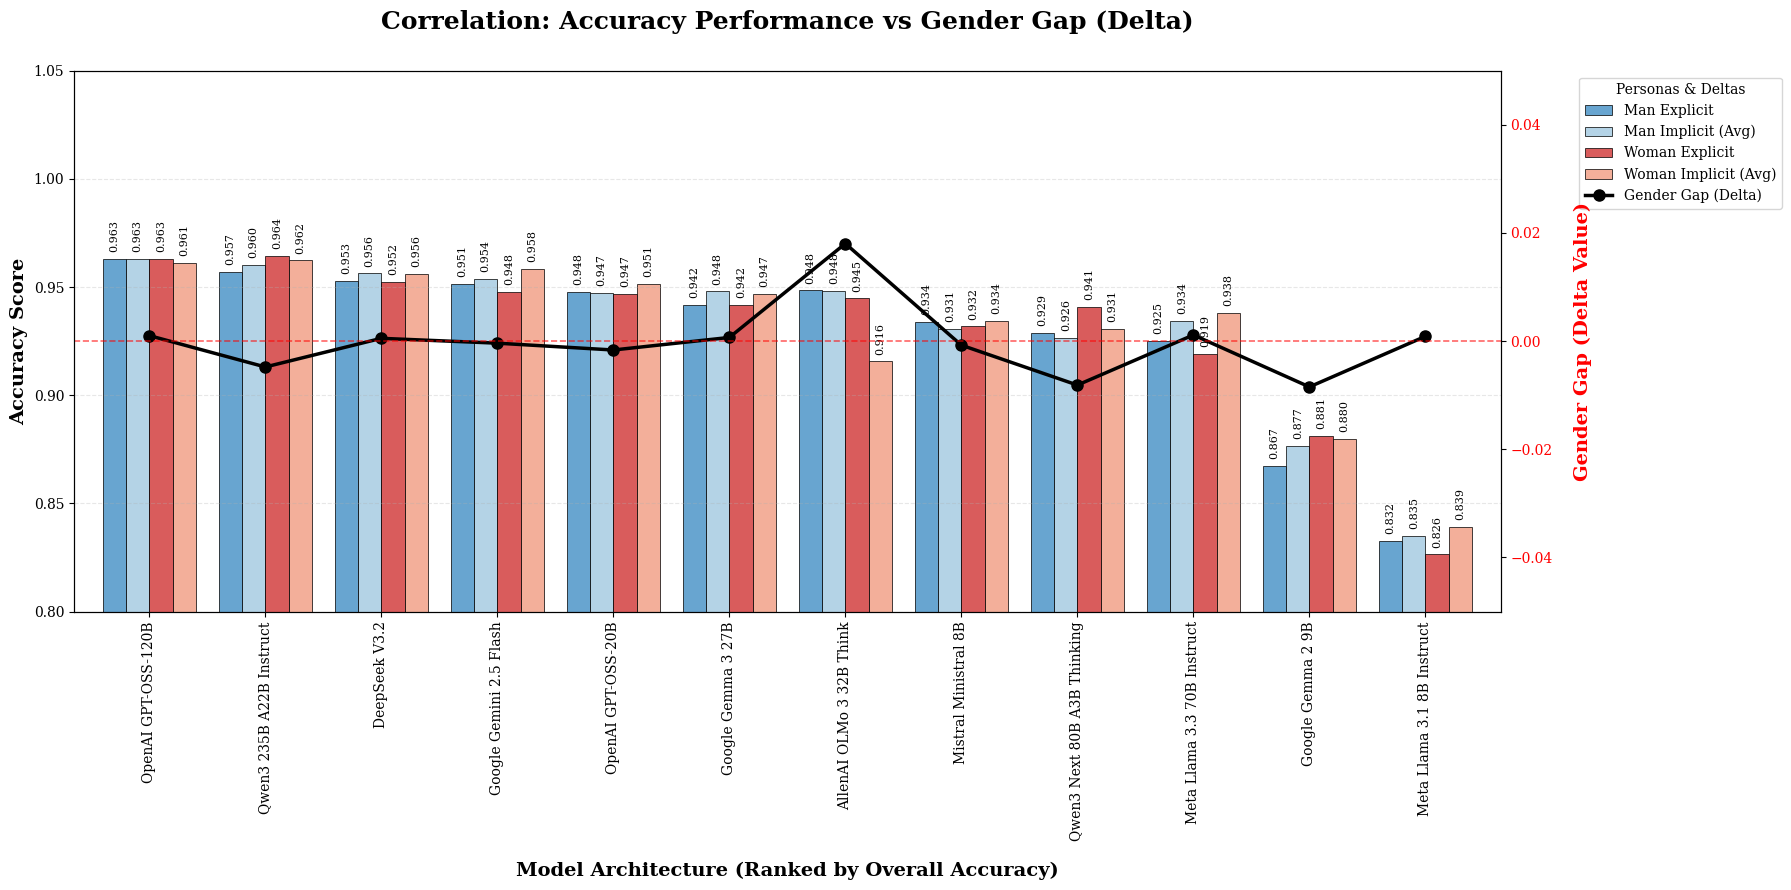

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# --- PREPARATION ---
# We use df_sorted (which we ranked by overall accuracy earlier)
# To make the chart tell a story of "Performance vs. Bias"
column_order = ['Man Explicit', 'Man Implicit (Avg)', 'Woman Explicit', 'Woman Implicit (Avg)']
colors = ['#4e96c8', '#a7cce2', '#d33f3f', '#f1a189'] # Clean blue-red palette

fig, ax1 = plt.subplots(figsize=(18, 9), dpi=100)
plt.rcParams['font.family'] = 'serif'

# --- AXIS 1: ACCURACY BARS ---
df_sorted[column_order].plot(kind='bar', ax=ax1, width=0.8, color=colors, edgecolor='black', linewidth=0.6, alpha=0.85)

# Setting limits for Accuracy (Left Y-Axis)
ax1.set_ylim(0.80, 1.05)
ax1.set_ylabel('Accuracy Score', fontsize=14, fontweight='bold')
ax1.set_xlabel('Model Architecture (Ranked by Overall Accuracy)', fontsize=14, fontweight='bold', labelpad=15)

# --- AXIS 2: GENDER GAP LINE (THE DELTA) ---
ax2 = ax1.twinx() # Create the dual axis
# Thinking far: Assigning a different color to the secondary axis for clarity
ax2.plot(range(len(df_sorted)), df_sorted['Gender Gap (Man-Woman)'],
         color='black', marker='o', markersize=8, linewidth=2.5, label='Gender Gap (Delta)')

# Setting limits for Delta (Right Y-Axis)
# We center 0.00 so the red dashed line is perfectly in the middle
ax2.set_ylim(-0.05, 0.05)
ax2.set_ylabel('Gender Gap (Delta Value)', fontsize=14, fontweight='bold', color='red', labelpad=15)
ax2.tick_params(axis='y', labelcolor='red')

# Ideal Neutrality Line (0.00)
ax2.axhline(0, color='red', linestyle='--', linewidth=1.2, alpha=0.6)

# --- ANNOTATIONS (BAR LABELS) ---
for p in ax1.patches:
    h = p.get_height()
    if h > 0:
        ax1.annotate(f'{h:.3f}', (p.get_x() + p.get_width()/2., h),
                     ha='center', va='bottom', xytext=(0, 5),
                     textcoords='offset points', fontsize=8, rotation=90)

# --- COSMETICS ---
ax1.set_title('Correlation: Accuracy Performance vs Gender Gap (Delta)', fontsize=18, fontweight='bold', pad=30)

# Cleaning Grids: Only keep horizontal ones for readability
ax1.grid(axis='y', linestyle='--', alpha=0.3)
ax1.grid(axis='x', visible=False) # Cermat: Remove vertical grids

# Legends Management
# Combining legends from both axes to show them together
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, title='Personas & Deltas',
           loc='upper left', bbox_to_anchor=(1.05, 1), frameon=True)

plt.xticks(rotation=45, ha='right', fontsize=10)
plt.tight_layout()
plt.show()

## Token Usage

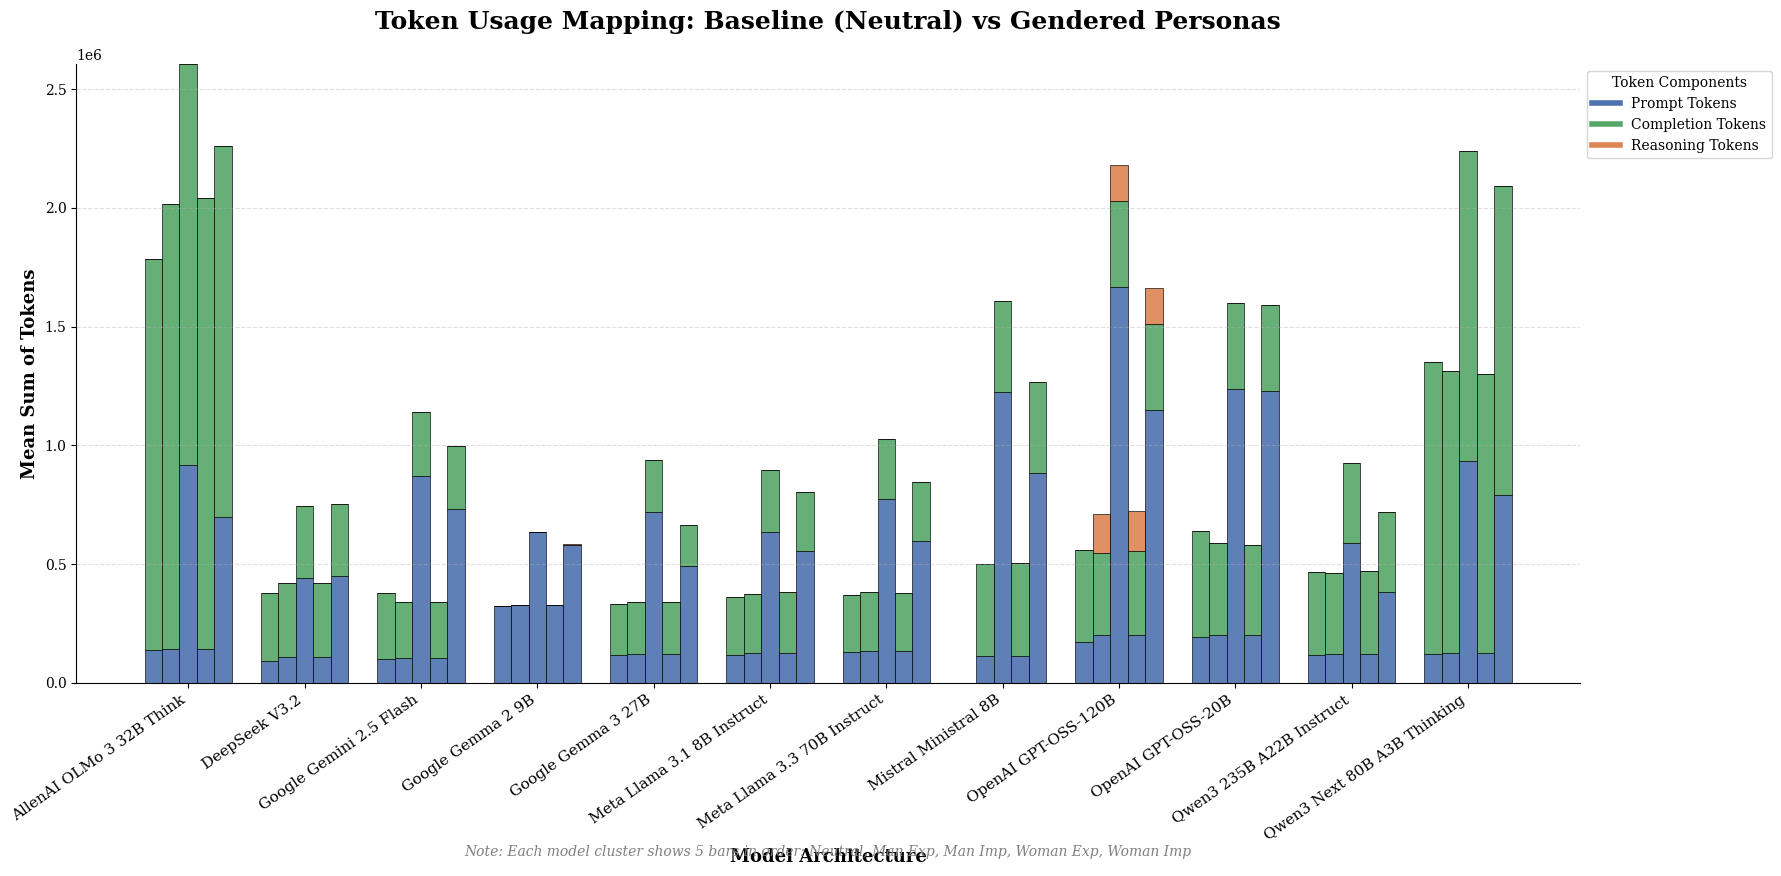

In [ ]:


# 2. Calculate Mean for Token Components (Sama seperti kodemu)
token_cols = ['Sum_Prompt_Tokens', 'Sum_Completion_Tokens', 'Sum_Reasoning_Tokens']
df_token_avg = df_full.groupby(['Model', 'Category'])[token_cols].mean().reset_index()
df_token_avg['Total_Calc'] = df_token_avg[token_cols].sum(axis=1)

# 3. Setup for Visualization
models = df_token_avg['Model'].unique()
# Urutan 5 batang: Neutral dulu baru yang lainnya
categories = ['Neutral', 'Man Explicit', 'Man Implicit (Avg)', 'Woman Explicit', 'Woman Implicit (Avg)']

# Professional Colors
colors = ['#4C72B0', '#55A868', '#DD8452']

# 4. Create the Plot
fig, ax = plt.subplots(figsize=(18, 9), dpi=100)

x = np.arange(len(models))
width = 0.15  # Abel: Lebar dikecilkan sedikit agar 5 batang muat rapi

for i, cat in enumerate(categories):
    # Filter data untuk kategori ini
    cat_data = df_token_avg[df_token_avg['Category'] == cat].set_index('Model').reindex(models).fillna(0)

    # Perubahan Posisi: Karena ada 5 batang (i=0..4),
    # titik tengahnya adalah i=2. Maka offsetnya (i - 2)
    pos = x + (i - 2) * width

    # Bottom for stacking
    bottom_val = np.zeros(len(models))

    for j, col in enumerate(token_cols):
        ax.bar(pos, cat_data[col], width, bottom=bottom_val,
               label=col.replace('Sum_', '').replace('_Tokens', '') if i == 0 else "",
               color=colors[j], edgecolor='black', linewidth=0.5, alpha=0.9)
        bottom_val += cat_data[col].values

# 5. Styling & Professionalism
ax.set_title('Token Usage Mapping: Baseline (Neutral) vs Gendered Personas', fontsize=18, fontweight='bold', pad=25)
ax.set_ylabel('Mean Sum of Tokens', fontsize=13, fontweight='bold')
ax.set_xlabel('Model Architecture', fontsize=13, fontweight='bold')

# X-axis handling
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=35, ha='right', fontsize=11)

# Legend
legend_elements = [Line2D([0], [0], color=colors[0], lw=4, label='Prompt Tokens'),
                   Line2D([0], [0], color=colors[1], lw=4, label='Completion Tokens'),
                   Line2D([0], [0], color=colors[2], lw=4, label='Reasoning Tokens')]
ax.legend(handles=legend_elements, title='Token Components', frameon=True, loc='upper left', bbox_to_anchor=(1, 1))

# Update Note untuk 5 batang
note_text = 'Note: Each model cluster shows 5 bars in order: Neutral, Man Exp, Man Imp, Woman Exp, Woman Imp'
ax.text(0.5, -0.28, note_text, transform=ax.transAxes, ha='center', fontsize=10, style='italic', color='gray')

# Aesthetics
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.yaxis.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

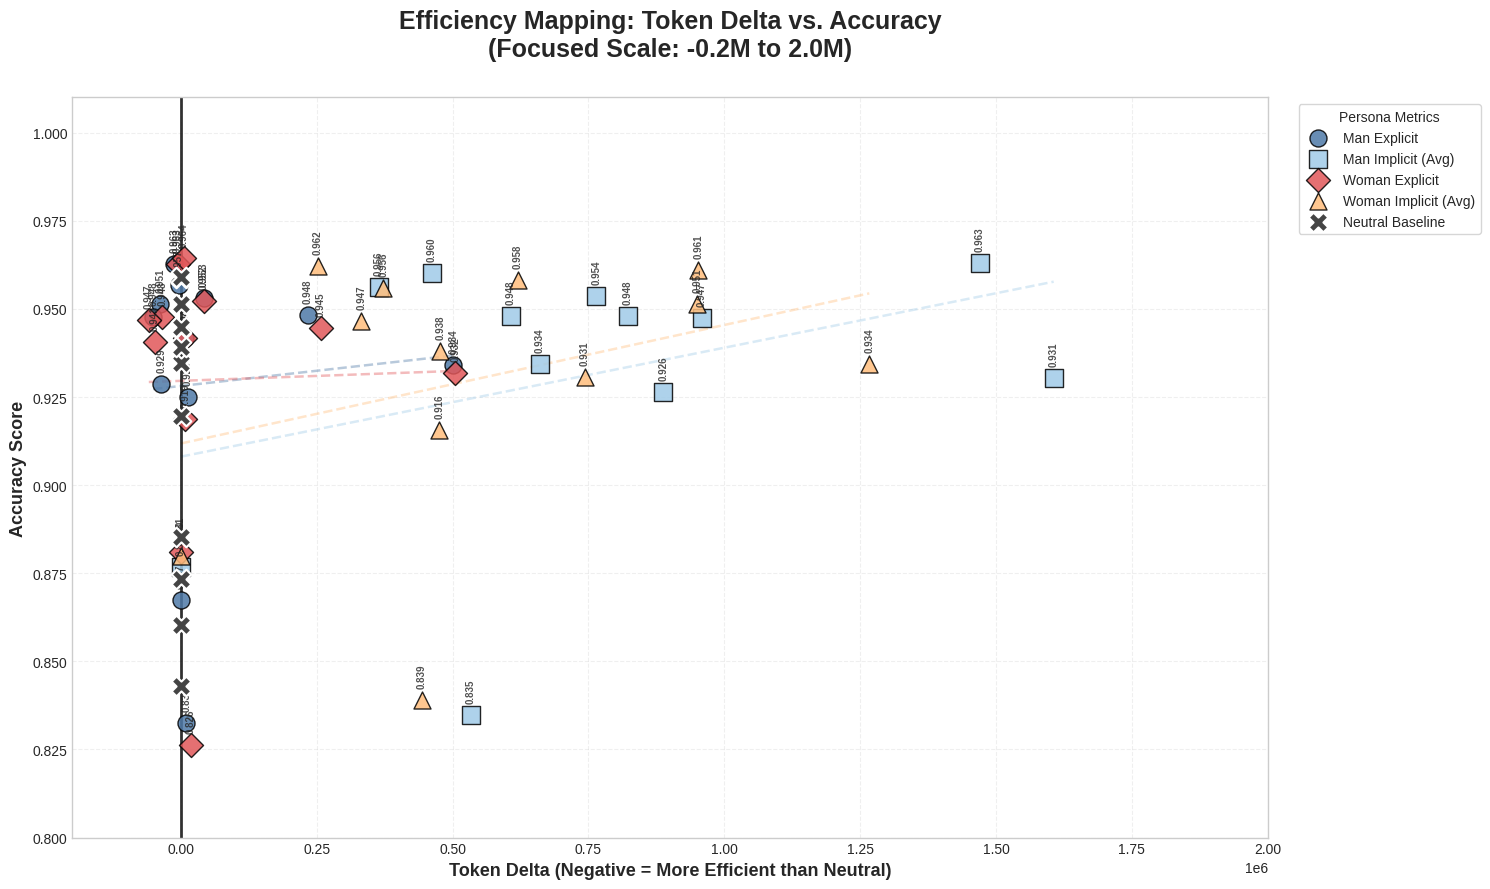

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# --- PREPARATION (Pastikan data df_influence sudah siap dari langkah sebelumnya) ---
# Categories & Styling
categories = ['Man Explicit', 'Man Implicit (Avg)', 'Woman Explicit', 'Woman Implicit (Avg)']
colors = ['#4e79a7', '#a0cbe8', '#e15759', '#ffbe7d']
markers = ['o', 's', 'D', '^']

plt.rcParams['font.family'] = 'serif'
plt.style.use('seaborn-v0_8-whitegrid')
fig, ax = plt.subplots(figsize=(15, 9), dpi=100)

# --- CORE VISUALIZATION ---
for i, cat in enumerate(categories):
    subset = df_influence[df_influence['Category'] == cat]
    if subset.empty: continue

    # Scatter points (X = Token_Delta, Y = Accuracy)
    ax.scatter(subset['Token_Delta'], subset['Accuracy'],
               s=150, color=colors[i], label=cat, marker=markers[i],
               edgecolor='black', alpha=0.85, zorder=3)

    # Trend line (Regression) per kategori
    if len(subset) > 1:
        sns.regplot(data=subset, x='Token_Delta', y='Accuracy',
                    scatter=False, ax=ax, color=colors[i], ci=None,
                    line_kws={'linestyle':'--', 'linewidth':1.8, 'alpha':0.4})

# Titik Neutral Baseline di (0, Accuracy_Neutral)
neutral_subset = df_influence[df_influence['Category'] == 'Neutral']
ax.scatter(np.zeros(len(neutral_subset)), neutral_subset['Accuracy'],
           s=200, color='#444444', label='Neutral Baseline', marker='X',
           edgecolor='white', linewidth=1.5, zorder=5)

# --- SCALE REFINEMENT (THE FIX: -0.2M to 2M) ---
# Abel, we are setting the limits exactly as requested to focus on the active data zone.
ax.set_xlim(-200000, 2000000)
ax.set_ylim(0.80, 1.01) # Tetap fokus di area performa tinggi

# Garis vertikal di X=0 (Neutral Baseline) yang tegas
ax.axvline(0, color='black', linewidth=2, linestyle='-', alpha=0.8, zorder=2)

# Annotations (Accuracy Labels)
for i in range(len(df_influence)):
    x_val = df_influence['Token_Delta'].iat[i]
    y_val = df_influence['Accuracy'].iat[i]
    # Hanya beri label jika titik berada di dalam range pandang agar tidak error
    if pd.notna(y_val) and -200000 <= x_val <= 2000000:
        if df_influence['Category'].iat[i] != 'Neutral':
            ax.annotate(f"{y_val:.3f}", (x_val, y_val), xytext=(0, 10),
                        textcoords='offset points', ha='center', fontsize=7,
                        fontweight='bold', rotation=90, alpha=0.8)

# --- FINAL COSMETICS ---
ax.set_title('Efficiency Mapping: Token Delta vs. Accuracy\n(Focused Scale: -0.2M to 2.0M)',
             fontsize=18, fontweight='bold', pad=30)
ax.set_xlabel('Token Delta (Negative = More Efficient than Neutral)', fontsize=13, fontweight='bold')
ax.set_ylabel('Accuracy Score', fontsize=13, fontweight='bold')

# Legend management
ax.legend(title='Persona Metrics', bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)

# Grid cleanup
ax.yaxis.grid(True, linestyle='--', alpha=0.3)
ax.xaxis.grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

## Model Size

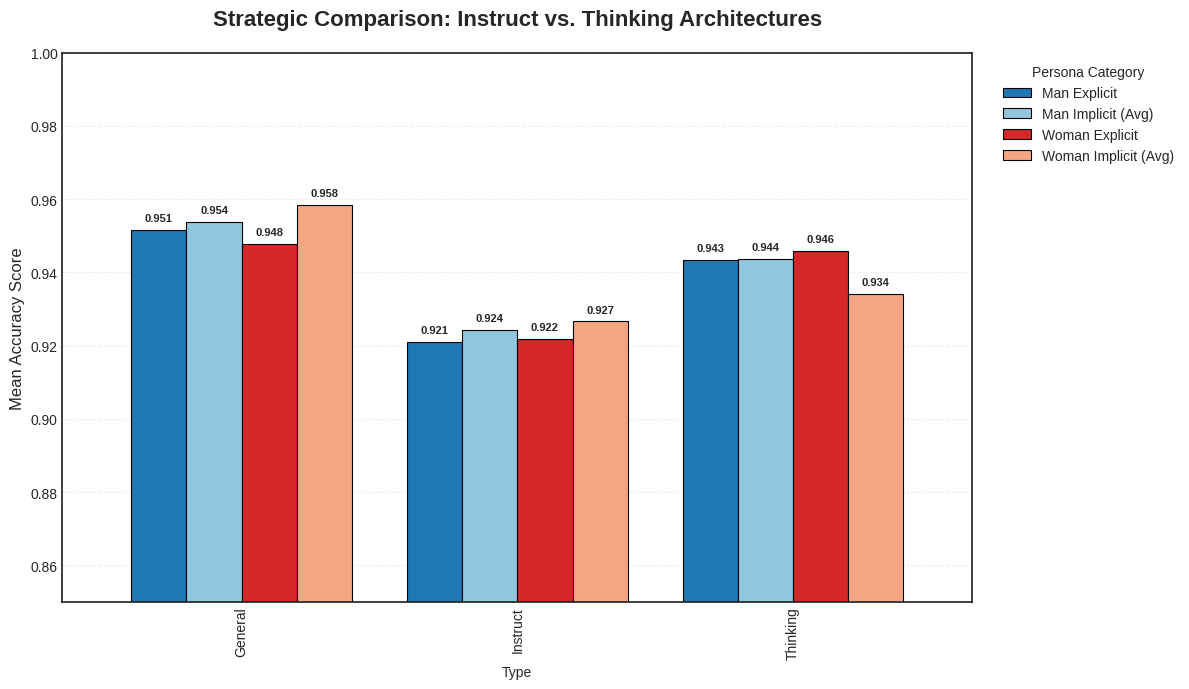

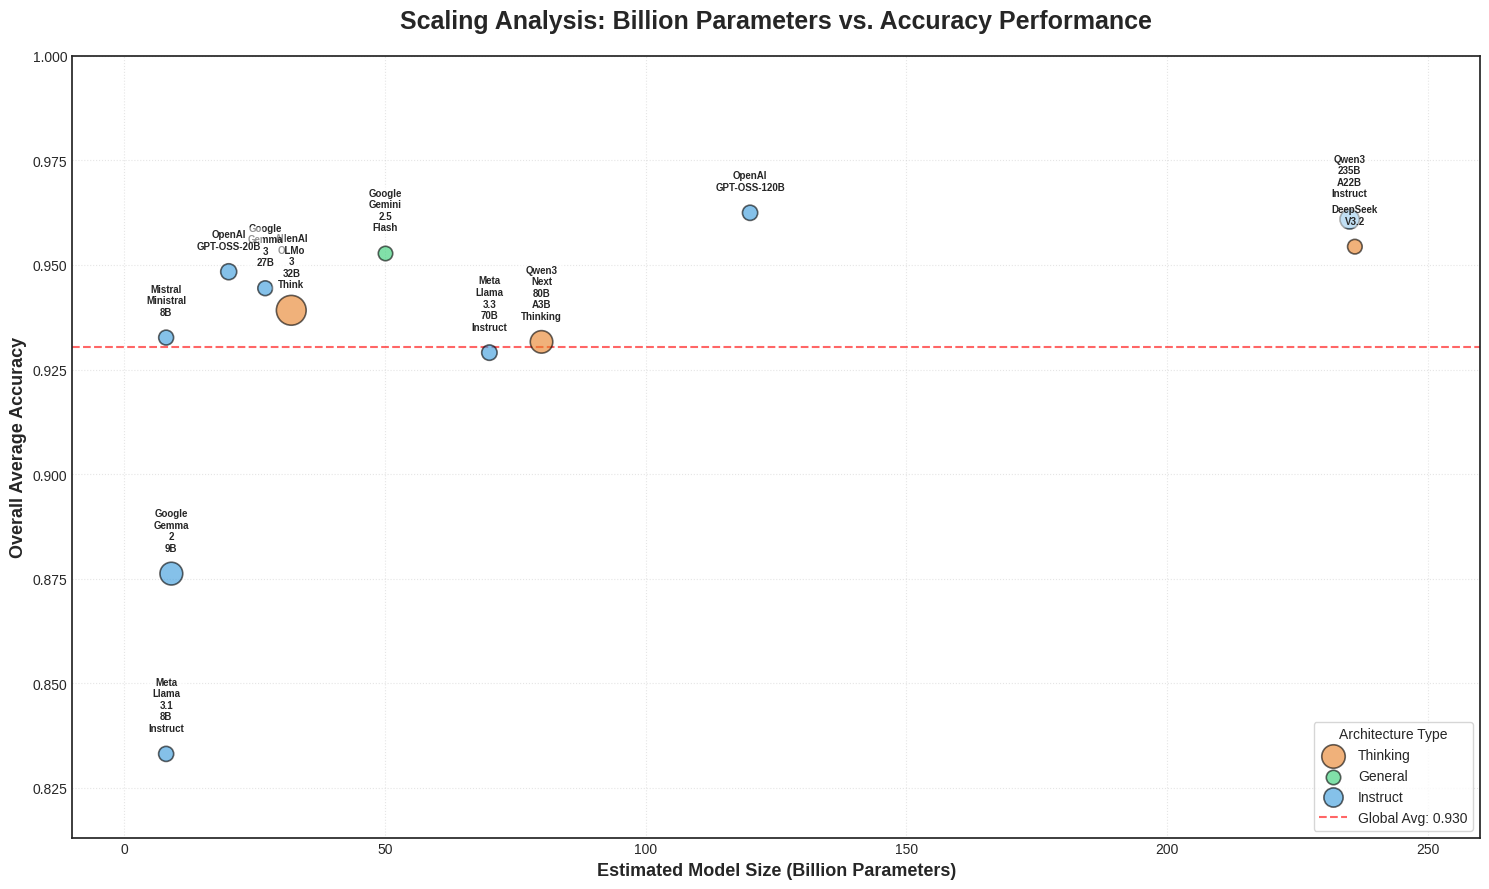

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns

# =============================================================================
# 1. ENHANCED DATA MAPPING
# =============================================================================
size_mapping = {
    'OpenAI GPT-OSS-20B': {'Size': 20, 'Category': 'Medium', 'Type': 'Instruct'},
    'Qwen3 Next 80B A3B Thinking': {'Size': 80, 'Category': 'Large', 'Type': 'Thinking'},
    'Qwen3 235B A22B Instruct': {'Size': 235, 'Category': 'Ultra Large', 'Type': 'Instruct'},
    'OpenAI GPT-OSS-120B': {'Size': 120, 'Category': 'Very Large', 'Type': 'Instruct'},
    'Meta Llama 3.3 70B Instruct': {'Size': 70, 'Category': 'Large', 'Type': 'Instruct'},
    'Google Gemma 3 27B': {'Size': 27, 'Category': 'Medium', 'Type': 'Instruct'},
    'Google Gemma 2 9B': {'Size': 9, 'Category': 'Small', 'Type': 'Instruct'},
    'DeepSeek V3.2': {'Size': 236, 'Category': 'Ultra Large', 'Type': 'Thinking'},
    'Google Gemini 2.5 Flash': {'Size': 50, 'Category': 'Proprietary', 'Type': 'General'},
    'Meta Llama 3.1 8B Instruct': {'Size': 8, 'Category': 'Small', 'Type': 'Instruct'},
    'Mistral Ministral 8B': {'Size': 8, 'Category': 'Small', 'Type': 'Instruct'},
    'AllenAI OLMo 3 32B Think': {'Size': 32, 'Category': 'Medium-Large', 'Type': 'Thinking'}
}

df_plot_size = df_pivot.copy()
df_plot_size['Size_Num'] = df_plot_size.index.map(lambda x: size_mapping.get(x, {}).get('Size', 0))
df_plot_size['Type'] = df_plot_size.index.map(lambda x: size_mapping.get(x, {}).get('Type', 'Unknown'))
df_plot_size['Overall_Acc'] = df_plot_size[['Man Explicit', 'Man Implicit (Avg)', 'Woman Explicit', 'Woman Implicit (Avg)']].mean(axis=1)

# Tambahan: Hitung Gap untuk ukuran Bubble nanti
df_plot_size['Gender_Gap_Abs'] = abs(
    (df_plot_size['Man Explicit'] + df_plot_size['Man Implicit (Avg)'])/2 -
    (df_plot_size['Woman Explicit'] + df_plot_size['Woman Implicit (Avg)'])/2
)

# =============================================================================
# 2. VISUALIZE BY MODEL TYPE (WITH COLOR CONSISTENCY)
# =============================================================================
plt.style.use('seaborn-v0_8-white')
fig, ax = plt.subplots(figsize=(12, 7))

# Abel: We use the same colors as before for persona consistency
persona_colors = ['#1f77b4', '#92c5de', '#d62728', '#f4a582']
column_order = ['Man Explicit', 'Man Implicit (Avg)', 'Woman Explicit', 'Woman Implicit (Avg)']

df_type = df_plot_size.groupby('Type')[column_order].mean()

# Plot bars
df_type.plot(kind='bar', ax=ax, width=0.8, color=persona_colors, edgecolor='black', linewidth=0.8)

# Add value labels on top of bars
for p in ax.patches:
    ax.annotate(f'{p.get_height():.3f}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=8, fontweight='bold', xytext=(0, 5), textcoords='offset points')

ax.set_title('Strategic Comparison: Instruct vs. Thinking Architectures', fontsize=16, fontweight='bold', pad=20)
ax.set_ylabel('Mean Accuracy Score', fontsize=12)
ax.set_ylim(0.85, 1.0) # Zoomed in for better contrast
ax.grid(axis='y', linestyle='--', alpha=0.3)
ax.legend(title='Persona Category', bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()

# =============================================================================
# 3. ENHANCED BUBBLE CHART (Size vs. Acc vs. Type)
# =============================================================================
fig, ax = plt.subplots(figsize=(15, 9))

# Professional Palette
type_colors = {'Instruct': '#3498db', 'Thinking': '#e67e22', 'General': '#2ecc71', 'Unknown': '#95a5a6'}

for m_type in df_plot_size['Type'].unique():
    subset = df_plot_size[df_plot_size['Type'] == m_type]

    # Thinking far: Bubble size represents the Gender Gap (Magnitude of Bias)
    # Scaling factor 20000 for high visibility
    bubble_size = subset['Gender_Gap_Abs'] * 20000 + 100

    ax.scatter(subset['Size_Num'], subset['Overall_Acc'],
               s=bubble_size, label=m_type, color=type_colors.get(m_type, 'gray'),
               alpha=0.6, edgecolors='black', linewidth=1.2, zorder=3)

# Annotate with smart offsets to avoid overlap
for i, txt in enumerate(df_plot_size.index):
    x_val = df_plot_size['Size_Num'].iat[i]
    y_val = df_plot_size['Overall_Acc'].iat[i]

    # Split long model names for better look
    clean_name = txt.replace(' ', '\n')

    ax.annotate(clean_name, (x_val, y_val),
                fontsize=7, fontweight='bold', xytext=(0, 15),
                textcoords='offset points', ha='center', va='bottom',
                bbox=dict(boxstyle='round,pad=0.2', fc='white', alpha=0.5, ec='none'))

# Global Average Line
avg_acc = df_plot_size['Overall_Acc'].mean()
plt.axhline(avg_acc, color='red', linestyle='--', alpha=0.6, linewidth=1.5,
            label=f'Global Avg: {avg_acc:.3f}', zorder=1)

ax.set_title('Scaling Analysis: Billion Parameters vs. Accuracy Performance', fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Estimated Model Size (Billion Parameters)', fontsize=13, fontweight='bold')
ax.set_ylabel('Overall Average Accuracy', fontsize=13, fontweight='bold')

# Formatting
ax.set_xlim(-10, 260) # Padding for Ultra Large models
ax.set_ylim(df_plot_size['Overall_Acc'].min() - 0.02, 1.0)
ax.legend(title='Architecture Type', loc='lower right', frameon=True, fontsize=10)
ax.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

In [ ]:
# 1. Ensure model type mapping exists
type_map = {
    'AllenAI OLMo 3 32B Think': 'Thinking',
    'DeepSeek V3.2': 'Thinking',
    'Qwen3 Next 80B A3B Thinking': 'Thinking',
    'OpenAI GPT-OSS-20B': 'Instruct',
    'OpenAI GPT-OSS-120B': 'Instruct',
    'Qwen3 235B A22B Instruct': 'Instruct',
    'Meta Llama 3.3 70B Instruct': 'Instruct',
    'Meta Llama 3.1 8B Instruct': 'Instruct',
    'Google Gemma 3 27B': 'Instruct',
    'Google Gemma 2 9B': 'Instruct',
    'Mistral Ministral 8B': 'Instruct',
    'Google Gemini 2.5 Flash': 'General'
}

# 2. Create token summary per model
df_tokens_summary = df_full.groupby('Model')['Sum_Total_Tokens'].mean().reset_index()

# 3. Add Type info
df_tokens_summary['Model_Type'] = df_tokens_summary['Model'].map(type_map)

# 4. Get average Accuracy from the previously created df_pivot
df_tokens_summary = df_tokens_summary.set_index('Model')
df_tokens_summary['Avg_Accuracy'] = df_pivot[['Man Explicit', 'Man Implicit (Avg)', 'Woman Explicit', 'Woman Implicit (Avg)']].mean(axis=1)

# Check the results
display(df_tokens_summary.head(12))

,Sum_Total_Tokens,Model_Type,Avg_Accuracy
Model,,,
AllenAI OLMo 3 32B Think,2.142300e+06,Thinking,0.939167
DeepSeek V3.2,5.440466e+05,Thinking,0.954375
Google Gemini 2.5 Flash,6.385498e+05,General,0.952805
Google Gemma 2 9B,0.000000e+00,Instruct,0.876232
Google Gemma 3 27B,5.237986e+05,Instruct,0.944442
Meta Llama 3.1 8B Instruct,5.634339e+05,Instruct,0.833144
Meta Llama 3.3 70B Instruct,5.999195e+05,Instruct,0.929050
Mistral Ministral 8B,7.758306e+05,Instruct,0.932647
OpenAI GPT-OSS-120B,1.040223e+06,Instruct,0.962469


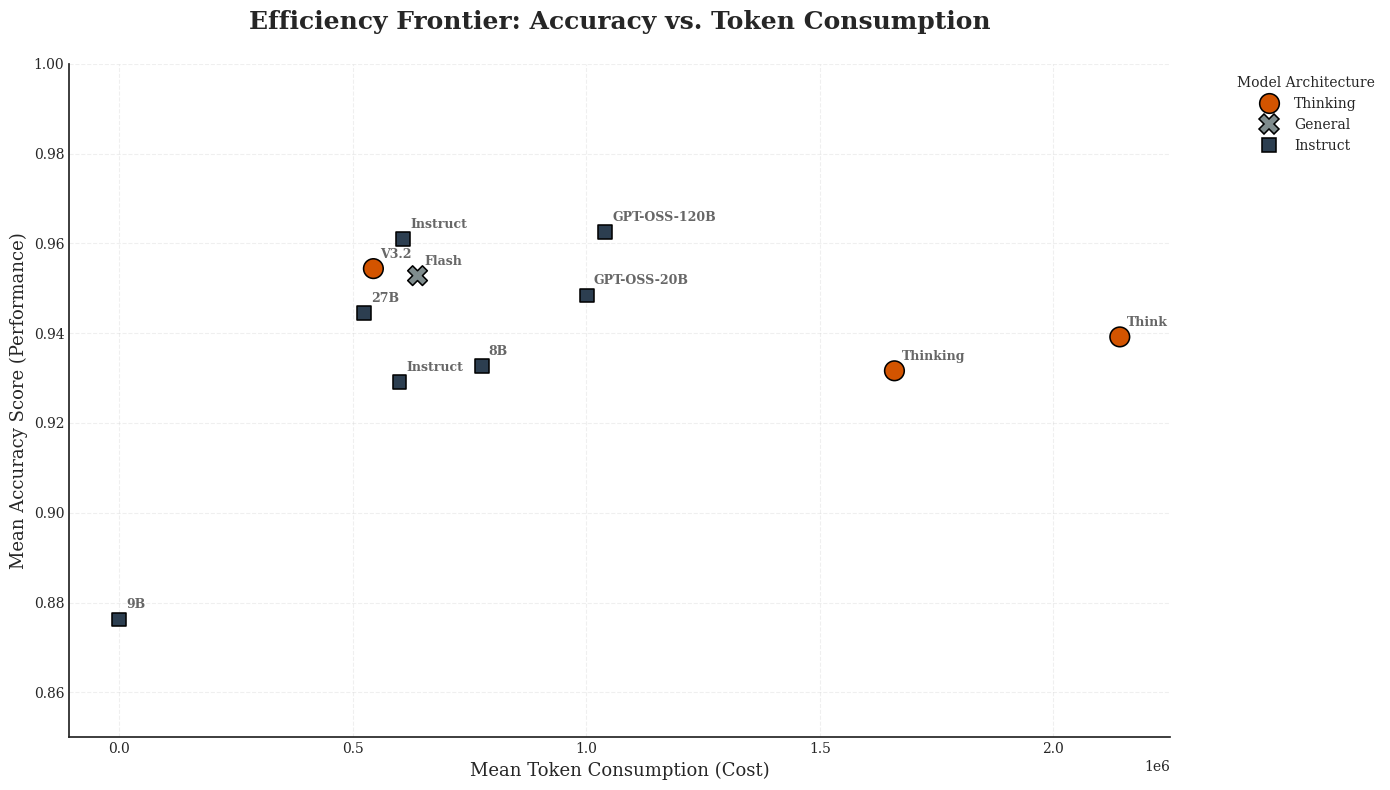

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['font.family'] = 'serif'
fig, ax = plt.subplots(figsize=(14, 8), dpi=100)

# Professional colors
palette = {'Instruct': '#2c3e50', 'Thinking': '#d35400', 'General': '#7f8c8d'}

# Plot Scatter
sns.scatterplot(
    data=df_tokens_summary,
    x='Sum_Total_Tokens',
    y='Avg_Accuracy',
    hue='Model_Type',
    style='Model_Type',
    palette=palette,
    s=200,
    edgecolor='black',
    ax=ax,
    zorder=3
)

# Add model name labels
for i in range(len(df_tokens_summary)):
    ax.annotate(
        df_tokens_summary.index[i].split(' ')[-1], # Take the last word for brevity
        (df_tokens_summary['Sum_Total_Tokens'].iat[i], df_tokens_summary['Avg_Accuracy'].iat[i]),
        xytext=(5, 8), textcoords='offset points',
        fontsize=9, fontweight='bold', alpha=0.7
    )

# Journal-style Formatting
ax.set_ylim(0.85, 1.0) # Focus on high accuracy
ax.set_title('Efficiency Frontier: Accuracy vs. Token Consumption', fontsize=18, pad=25, fontweight='bold')
ax.set_xlabel('Mean Token Consumption (Cost)', fontsize=13)
ax.set_ylabel('Mean Accuracy Score (Performance)', fontsize=13)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(True, linestyle='--', alpha=0.3)

plt.legend(title='Model Architecture', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [ ]:
# 1. Calculate Mean and Std from raw data (Neutral included)
# Pastikan 'Neutral' ada di kolom Category
df_stats = df_full.groupby(['Model', 'Category'])['Accuracy'].agg(['mean', 'std']).reset_index()

# 2. Pivot for Mean and Std
df_mean = df_stats.pivot(index='Model', columns='Category', values='mean')
df_std = df_stats.pivot(index='Model', columns='Category', values='std')

# Abel: Masukkan Neutral di urutan pertama sebagai benchmark
column_order = ['Neutral', 'Man Explicit', 'Man Implicit (Avg)', 'Woman Explicit', 'Woman Implicit (Avg)']

# Reindex hanya kolom yang ada untuk menghindari error
existing_cols = [col for col in column_order if col in df_mean.columns]
df_mean = df_mean[existing_cols]
df_std = df_std[existing_cols].fillna(0)

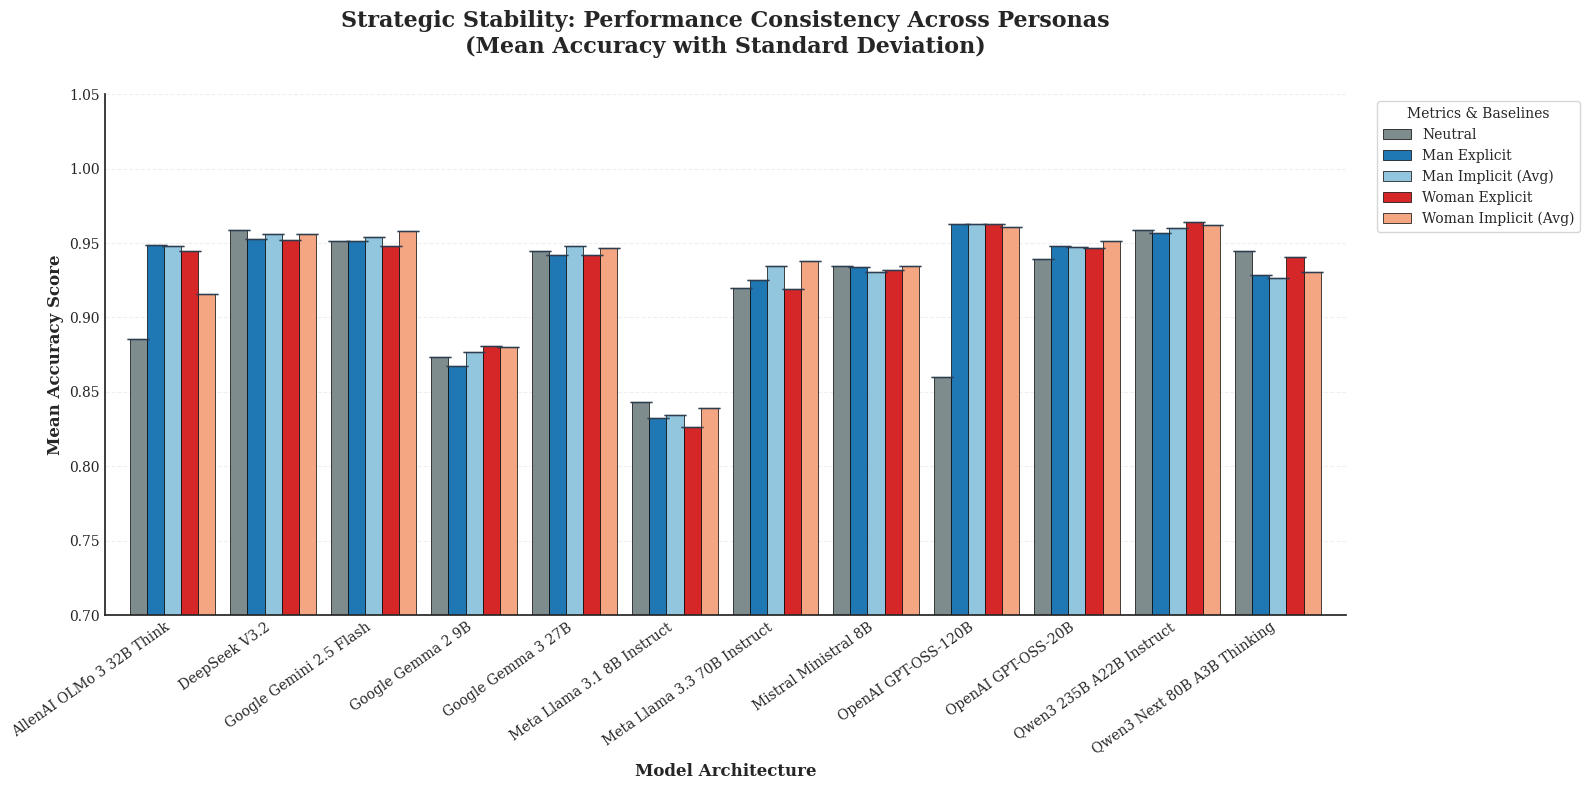

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# =============================================================================
# 1. DATA PREPARATION (LOGIKA MEAN & STD)
# =============================================================================

# Abel, pastikan df_full adalah dataframe mentah yang berisi semua percobaanmu
# Kita hitung statistik dasar untuk Accuracy
df_stats = df_full.groupby(['Model', 'Category'])['Accuracy'].agg(['mean', 'std']).reset_index()

# Pivot data untuk Mean dan Standard Deviation
df_mean = df_stats.pivot(index='Model', columns='Category', values='mean')
df_std = df_stats.pivot(index='Model', columns='Category', values='std')

# Menentukan urutan kolom agar 'Neutral' menjadi baseline di paling kiri
column_order = ['Neutral', 'Man Explicit', 'Man Implicit (Avg)', 'Woman Explicit', 'Woman Implicit (Avg)']

# Filter hanya kolom yang benar-benar ada di dataframe untuk menghindari error
existing_cols = [col for col in column_order if col in df_mean.columns]
df_mean = df_mean[existing_cols]
df_std = df_std[existing_cols].fillna(0) # Jika Std tidak ada (data tunggal), kita set 0

# =============================================================================
# 2. VISUALIZATION (ERROR BARS FOCUS)
# =============================================================================

plt.rcParams['font.family'] = 'serif'
fig, ax = plt.subplots(figsize=(16, 8), dpi=100)

# Professional colors: Abu-abu untuk Neutral, Biru untuk Man, Merah/Oranye untuk Woman
colors = ['#7f8c8d', '#1f77b4', '#92c5de', '#d62728', '#f4a582']

# Plot Bar dengan Error Bars
# Abel, aku pertegas elinewidth dan capsize-nya agar 'kumis' grafiknya terlihat tajam
df_mean.plot(kind='bar', ax=ax, width=0.85, color=colors,
             edgecolor='black', linewidth=0.5,
             yerr=df_std,
             capsize=8,
             error_kw={'elinewidth':2.0, 'ecolor':'#2c3e50', 'alpha':0.8})

# Focus Scale: Mulai dari 0.7 agar variansi terlihat lebih signifikan
ax.set_ylim(0.7, 1.05)

# Penamaan yang lebih akademis untuk paper/tesis
ax.set_title('Strategic Stability: Performance Consistency Across Personas\n(Mean Accuracy with Standard Deviation)',
             fontsize=16, fontweight='bold', pad=30)
ax.set_ylabel('Mean Accuracy Score', fontsize=12, fontweight='bold')
ax.set_xlabel('Model Architecture', fontsize=12, fontweight='bold')

# Styling & Grid
ax.yaxis.grid(True, linestyle='--', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Memastikan label sumbu X terbaca jelas
plt.xticks(rotation=35, ha='right', fontsize=10)

# Legend Configuration
ax.legend(title='Metrics & Baselines', bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)

plt.tight_layout()
plt.show()

In [ ]:
# 1. Pastikan df_stats sudah terhitung (Mean & Std)
df_stats = df_full.groupby(['Model', 'Category'])['Accuracy'].agg(['mean', 'std']).reset_index()

# 2. Filter: Implicit + Neutral (Sebagai Baseline)
# Berpikir jauh: Memasukkan Neutral untuk melihat 'gap' efisiensi
target_categories = ['Neutral', 'Man Implicit (Avg)', 'Woman Implicit (Avg)']
df_filtered_stats = df_stats[df_stats['Category'].isin(target_categories)]

# 3. Re-pivot
df_mean_imp = df_filtered_stats.pivot(index='Model', columns='Category', values='mean')
df_std_imp = df_filtered_stats.pivot(index='Model', columns='Category', values='std').fillna(0)

# 4. Sorting Columns (Urutan Baseline dulu)
# Abel, pastikan Neutral di paling kiri agar perbandingannya enak dilihat
col_order = ['Neutral', 'Man Implicit (Avg)', 'Woman Implicit (Avg)']
df_mean_imp = df_mean_imp[col_order]
df_std_imp = df_std_imp[col_order]

# Tampilkan hasil untuk verifikasi
display(df_mean_imp.head())

Category,Neutral,Man Implicit (Avg),Woman Implicit (Avg)
Model,,,
AllenAI OLMo 3 32B Think,0.885300,0.947967,0.915600
DeepSeek V3.2,0.958900,0.956267,0.956033
Google Gemini 2.5 Flash,0.951331,0.953753,0.958302
Google Gemma 2 9B,0.873293,0.876674,0.879960
Google Gemma 3 27B,0.944600,0.947941,0.946584


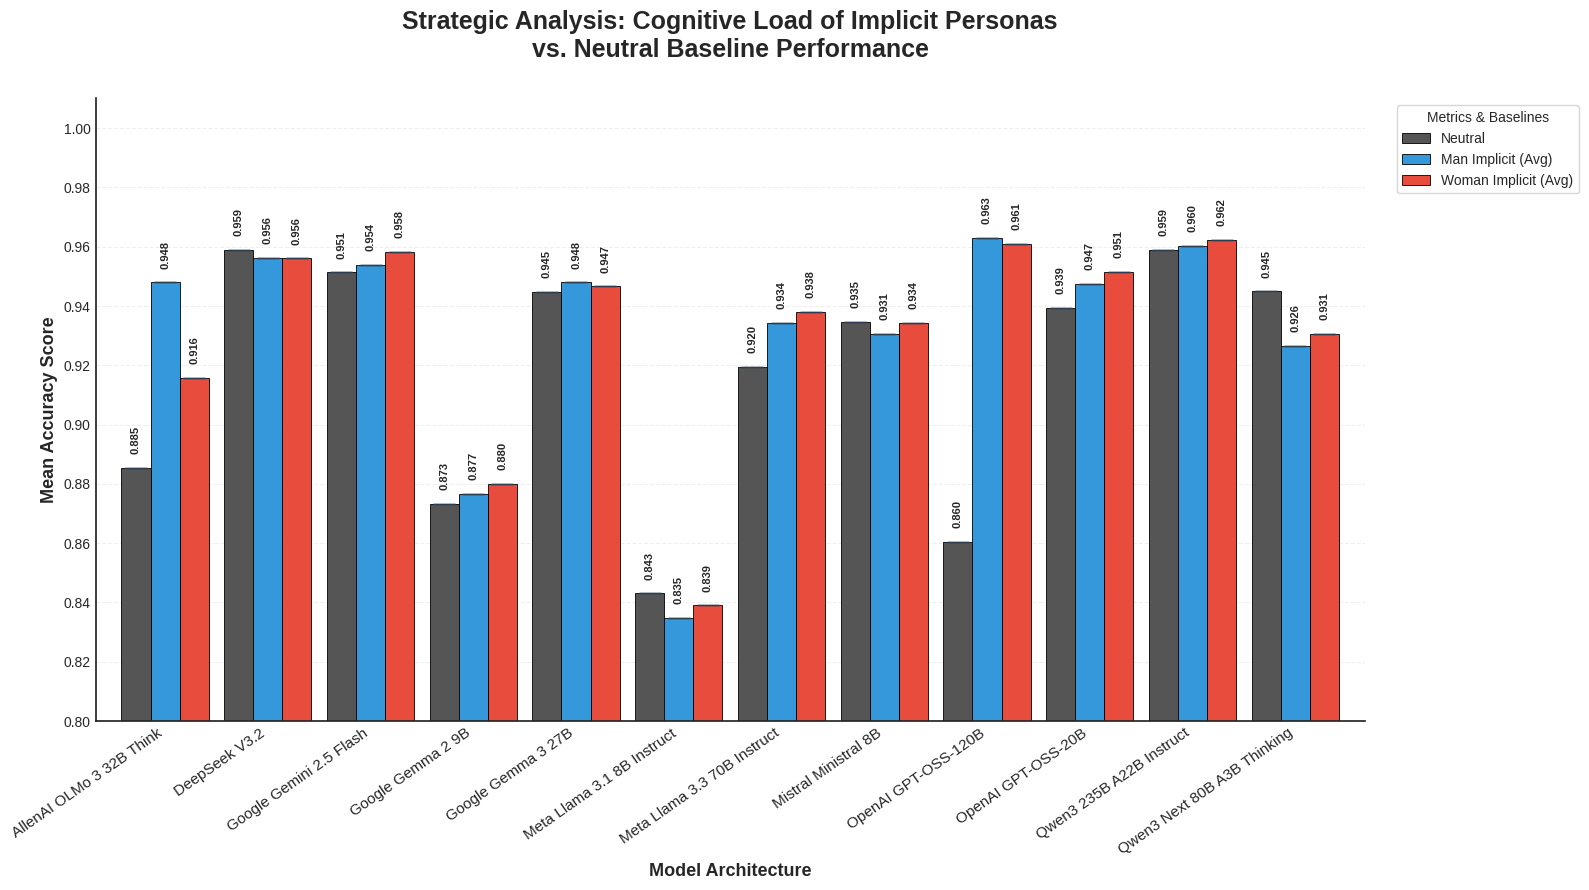

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# =============================================================================
# VISUALIZATION: IMPLICIT VS NEUTRAL BASELINE
# =============================================================================

# Abel: Menggunakan gaya serif agar terlihat akademis dan profesional
plt.rcParams['font.family'] = 'serif'
plt.style.use('seaborn-v0_8-white')
fig, ax = plt.subplots(figsize=(16, 9), dpi=100)

# Abel: Kita gunakan warna yang kontras terhadap Neutral
# Abu-abu Tua untuk Neutral (Anchor), Biru Terang untuk Man Imp, Merah Terang untuk Woman Imp
colors = ['#555555', '#3498db', '#e74c3c']

# Cermat: Pastikan urutan plotting sama dengan 'col_order' di langkah sebelumnya
# ['Neutral', 'Man Implicit (Avg)', 'Woman Implicit (Avg)']
df_mean_imp.plot(kind='bar', ax=ax, width=0.85, color=colors,
                 edgecolor='black', linewidth=0.6,
                 yerr=df_std_imp, capsize=8, # 'Kumis' (error bars) dipertegas
                 error_kw={'elinewidth':1.8, 'ecolor':'#2c3e50'})

# =============================================================================
# SCALE & CLUTTER REDUCTION
# =============================================================================

# Berpikir jauh: Zoom skala Y agar perbandingan desimal kecil terlihat signifikan
ax.set_ylim(0.80, 1.01) # Mulai dari 0.8 agar perbedaan 1-2% terlihat nyata
plt.yticks(np.arange(0.80, 1.01, 0.02)) # Garis grid setiap 0.02 untuk akurasi

# Judul yang akademis untuk tesis
ax.set_title('Strategic Analysis: Cognitive Load of Implicit Personas\nvs. Neutral Baseline Performance',
             fontsize=18, fontweight='bold', pad=30)
ax.set_ylabel('Mean Accuracy Score', fontsize=13, fontweight='bold')
ax.set_xlabel('Model Architecture', fontsize=13, fontweight='bold')

# Annotations (Accuracy Labels)
# Thinking far: Agar tidak menumpuk, kita hanya beri label jika batang terlihat penuh
for p in ax.patches:
    height = p.get_height()
    if pd.notna(height) and height > 0:
        ax.annotate(f'{height:.3f}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom',
                    xytext=(0, 10), # Posisi label sedikit di atas batang
                    textcoords='offset points',
                    fontsize=8,
                    fontweight='bold',
                    rotation=90) # Diputar 90 derajat agar tidak saling tabrak

# Aesthetics
ax.yaxis.grid(True, linestyle='--', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Memastikan label model di sumbu X terbaca jelas
plt.xticks(rotation=35, ha='right', fontsize=11)

# Legend di luar agar tidak menutupi batang
ax.legend(title='Metrics & Baselines', bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)

plt.tight_layout()
plt.show()

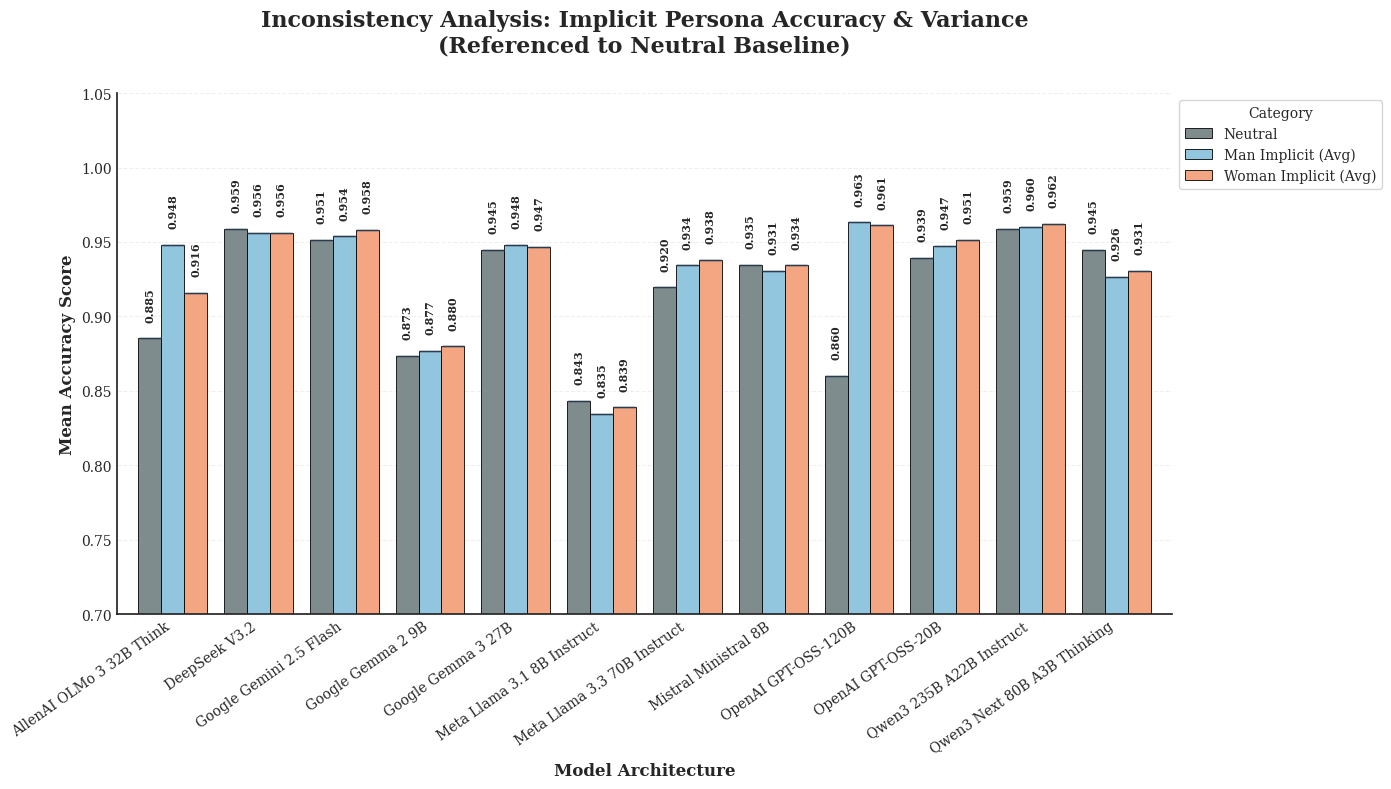

In [ ]:
import matplotlib.pyplot as plt

# --- PREPARATION ---
plt.rcParams['font.family'] = 'serif'
fig, ax = plt.subplots(figsize=(14, 8), dpi=100)

# Berpikir Cermat: Kita butuh 3 warna karena ada Neutral + 2 Implicits
# Abu-abu (Neutral), Biru Muda (Man Imp), Oranye Muda (Woman Imp)
colors_imp_full = ['#7f8c8d', '#92c5de', '#f4a582']

# Plot Bar with Error Bars (yerr=df_std_imp)
# Abel, pastikan df_mean_imp punya 3 kolom sesuai col_order sebelumnya
df_mean_imp.plot(kind='bar', ax=ax, width=0.8, color=colors_imp_full,
                 edgecolor='black', linewidth=0.6,
                 yerr=df_std_imp, capsize=8,
                 error_kw={'elinewidth':2, 'ecolor':'#2c3e50', 'alpha':0.8})

# --- SCALE & STYLING ---
# Abel, aku atur skalanya agar 'kumis' (variance) terlihat lebih dramatis
ax.set_ylim(0.70, 1.05)

ax.set_title('Inconsistency Analysis: Implicit Persona Accuracy & Variance\n(Referenced to Neutral Baseline)',
             fontsize=16, fontweight='bold', pad=30)
ax.set_ylabel('Mean Accuracy Score', fontsize=12, fontweight='bold')
ax.set_xlabel('Model Architecture', fontsize=12, fontweight='bold')

# Tambahkan label angka di atas kumis/batang
for p in ax.patches:
    h = p.get_height()
    if h > 0:
        ax.annotate(f'{h:.3f}', (p.get_x() + p.get_width()/2., h),
                     ha='center', va='bottom', xytext=(0, 12),
                     textcoords='offset points', fontsize=8, fontweight='bold', rotation=90)

ax.yaxis.grid(True, linestyle='--', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.xticks(rotation=35, ha='right')
# Legend disesuaikan posisinya agar tidak menutupi error bar
ax.legend(title='Category', loc='upper left', bbox_to_anchor=(1, 1), frameon=True)

plt.tight_layout()
plt.show()

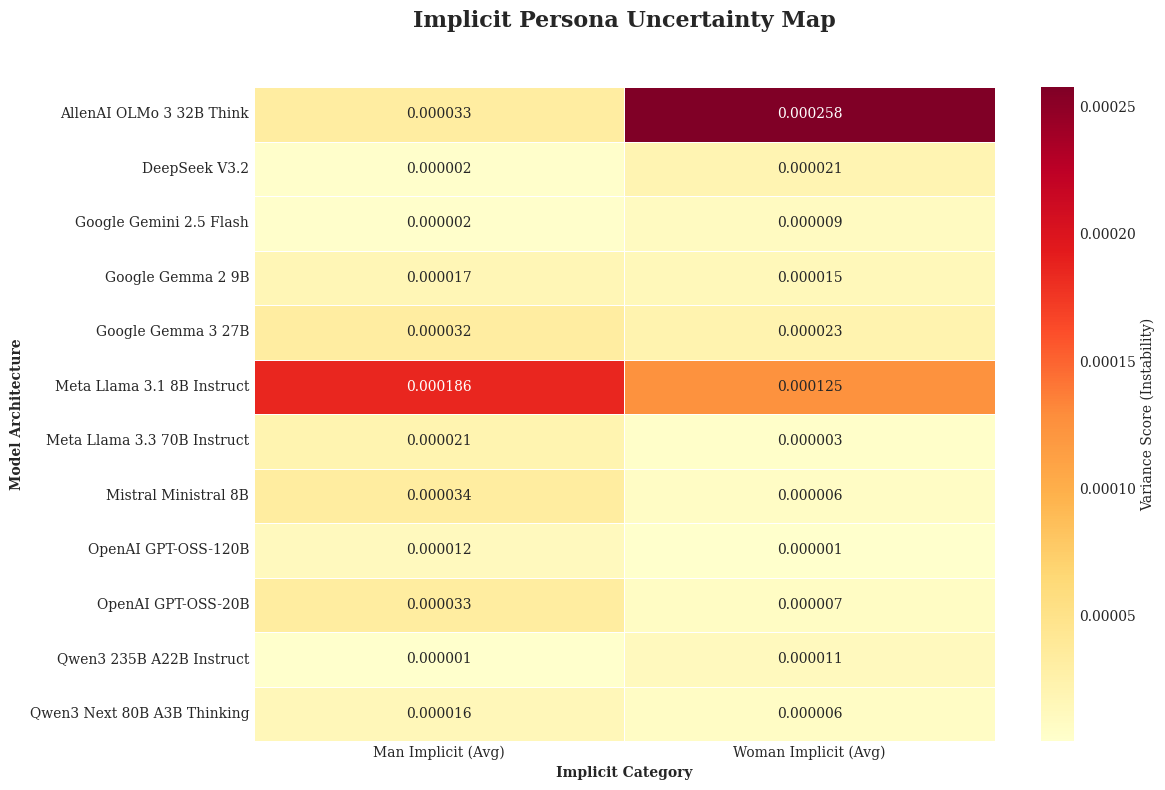

In [ ]:
# 1. Hitung Statistik (Mean & Variance) langsung dari df_raw
# Kita pake 'var' (Varians) karena kamu ingin memplot Variance Map
df_stats_raw = df_raw.groupby(['Model', 'Category'])['Accuracy'].agg(['mean', 'var']).reset_index()

# 2. Filter hanya untuk kategori Implicit (Sesuai maumu, tanpa Neutral)
implicit_list = ['Man Implicit (Avg)', 'Woman Implicit (Avg)']
# Abel, kalau kamu punya sub-kategori implicit lain, tambahkan di list ini ya
df_imp_var = df_stats_raw[df_stats_raw['Category'].isin(implicit_list)]

# 3. Pivot data untuk Heatmap (pilih nilai 'var')
df_var_heatmap = df_imp_var.pivot(index='Model', columns='Category', values='var').fillna(0)

# 4. Visualisasi Heatmap
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8), dpi=100)
plt.rcParams['font.family'] = 'serif'

# Abel: Kita pake cmap 'YlOrRd' agar area yang 'High Variance' terlihat merah (waspada)
sns.heatmap(df_var_heatmap,
            annot=True,
            cmap='YlOrRd',
            fmt='.6f',
            linewidths=0.5,
            cbar_kws={'label': 'Variance Score (Instability)'})

plt.title('Implicit Persona Uncertainty Map\n',
          fontsize=16, fontweight='bold', pad=25)
plt.ylabel('Model Architecture', fontweight='bold')
plt.xlabel('Implicit Category', fontweight='bold')

plt.tight_layout()
plt.show()

In [ ]:
# 1. Map size categories according to your list
size_cat_map = {
    'Google Gemma 2 9B': 'Small (7B–10B)',
    'Meta Llama 3.1 8B Instruct': 'Small (7B–10B)',
    'Mistral Ministral 8B': 'Small (7B–10B)',
    'OpenAI GPT-OSS-20B': 'Medium (15B–30B)',
    'Google Gemma 3 27B': 'Medium (15B–30B)',
    'AllenAI OLMo 3 32B Think': 'Medium-Large (30B–50B)',
    'Meta Llama 3.3 70B Instruct': 'Large (70B–100B)',
    'Qwen3 Next 80B A3B Thinking': 'Large (70B–100B)',
    'OpenAI GPT-OSS-120B': 'Very Large (100B–200B)',
    'Qwen3 235B A22B Instruct': 'Ultra Large (200B+)',
    'DeepSeek V3.2': 'Ultra Large (200B+)',
    'Google Gemini 2.5 Flash': 'Proprietary'
}

# 2. Add size category info to df_stats
df_stats['Size_Category'] = df_stats['Model'].map(size_cat_map)

# 3. Filter only Implicit
df_imp_size = df_stats[df_stats['Category'].isin(['Man Implicit (Avg)', 'Woman Implicit (Avg)'])]

# 4. Order Size Categories (to sort the graph from small to large)
size_order = [
    'Small (7B–10B)', 'Medium (15B–30B)', 'Medium-Large (30B–50B)',
    'Large (70B–100B)', 'Very Large (100B–200B)', 'Ultra Large (200B+)', 'Proprietary'
]

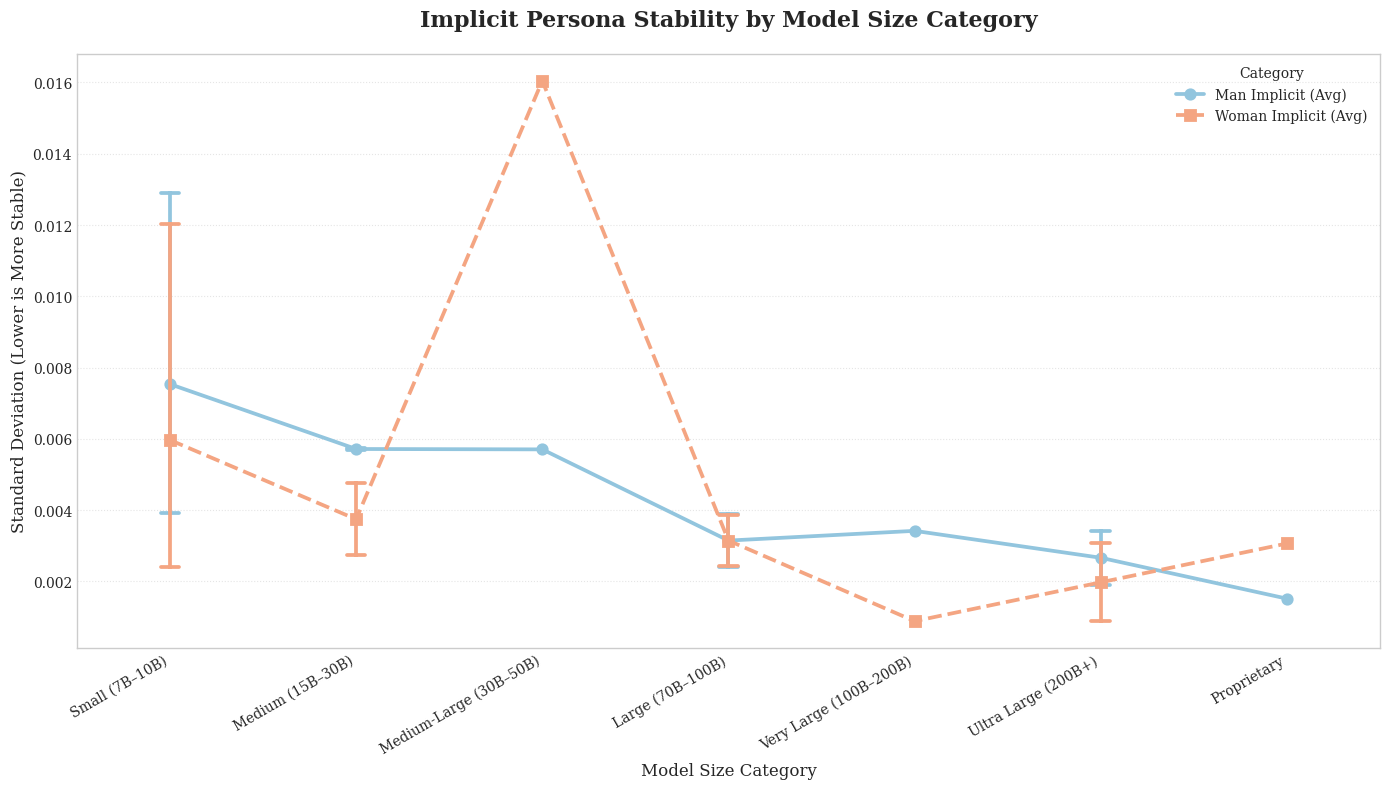

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 8))
plt.rcParams['font.family'] = 'serif'

# Visualize Standard Deviation trend by size
sns.pointplot(
    data=df_imp_size,
    x='Size_Category', y='std', hue='Category',
    order=size_order, palette=['#92c5de', '#f4a582'],
    markers=["o", "s"], linestyles=["-", "--"], capsize=.1
)

plt.title('Implicit Persona Stability by Model Size Category', fontsize=16, fontweight='bold', pad=20)
plt.ylabel('Standard Deviation (Lower is More Stable)', fontsize=12)
plt.xlabel('Model Size Category', fontsize=12)
plt.xticks(rotation=30, ha='right')
plt.grid(axis='y', linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

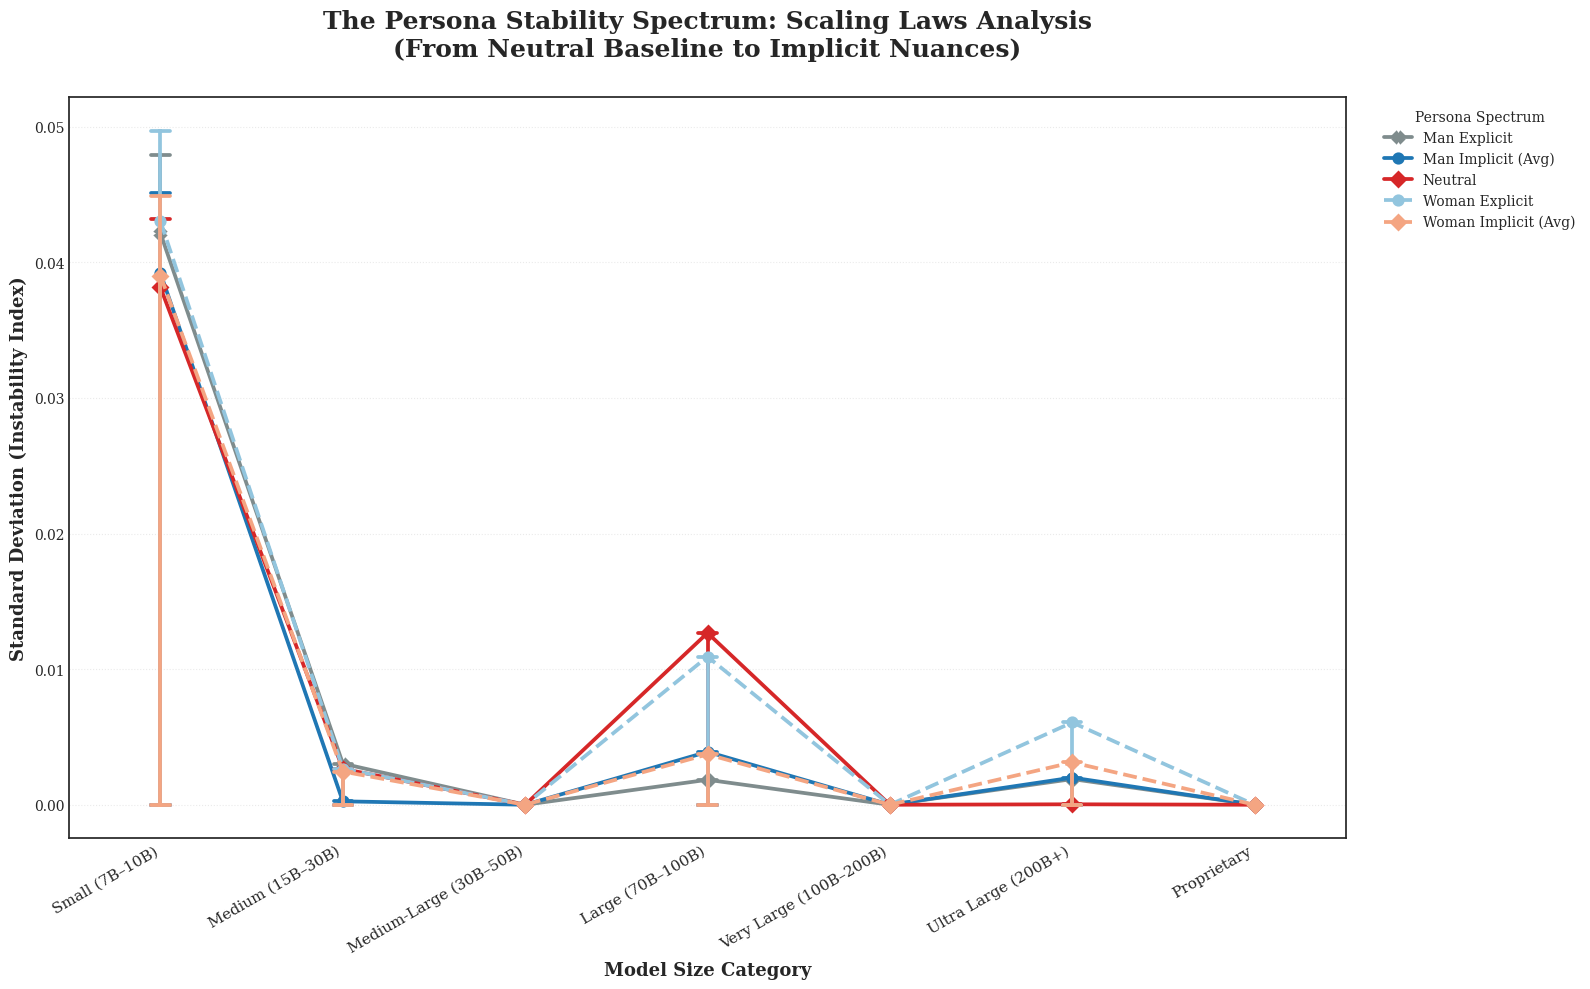

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# 1. Gunakan df_full (Raw Data) & Mapping Size
df_master = df_full.copy()
df_master['Size_Category'] = df_master['Model'].map(size_cat_map)

# 2. Filter 5 Kategori Utama (Spectrum Lengkap)
target_spectrum = [
    'Neutral',
    'Man Explicit', 'Woman Explicit',
    'Man Implicit (Avg)', 'Woman Implicit (Avg)'
]
df_master_filtered = df_master[df_master['Category'].isin(target_spectrum)]

# 3. Setup Urutan & Style
size_order = [
    'Small (7B–10B)', 'Medium (15B–30B)', 'Medium-Large (30B–50B)',
    'Large (70B–100B)', 'Very Large (100B–200B)', 'Ultra Large (200B+)', 'Proprietary'
]

# Palette Gradasi: Neutral (Abu), Explicit (Tegas), Implicit (Muda)
palette_5 = ['#7f8c8d', '#1f77b4', '#d62728', '#92c5de', '#f4a582']
markers_5 = ["X", "o", "D", "o", "D"]
lines_5 = ["-", "-", "-", "--", "--"] # Implicit dibikin putus-putus biar beda

# 4. Visualisasi
plt.figure(figsize=(16, 10), dpi=100)
plt.rcParams['font.family'] = 'serif'

sns.pointplot(
    data=df_master_filtered,
    x='Size_Category',
    y='Accuracy',           # Masukkan Accuracy mentah
    hue='Category',
    order=size_order,
    palette=palette_5,
    estimator=np.std,       # Biar Y-axis jadi Standard Deviation otomatis
    markers=markers_5,
    linestyles=lines_5,
    capsize=.1
)

# 5. Styling & Title
plt.title('The Persona Stability Spectrum: Scaling Laws Analysis\n(From Neutral Baseline to Implicit Nuances)',
          fontsize=18, fontweight='bold', pad=30)
plt.ylabel('Standard Deviation (Instability Index)', fontsize=13, fontweight='bold')
plt.xlabel('Model Size Category', fontsize=13, fontweight='bold')

plt.xticks(rotation=30, ha='right', fontsize=11)
plt.grid(axis='y', linestyle=':', alpha=0.4)
plt.legend(title='Persona Spectrum', bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()

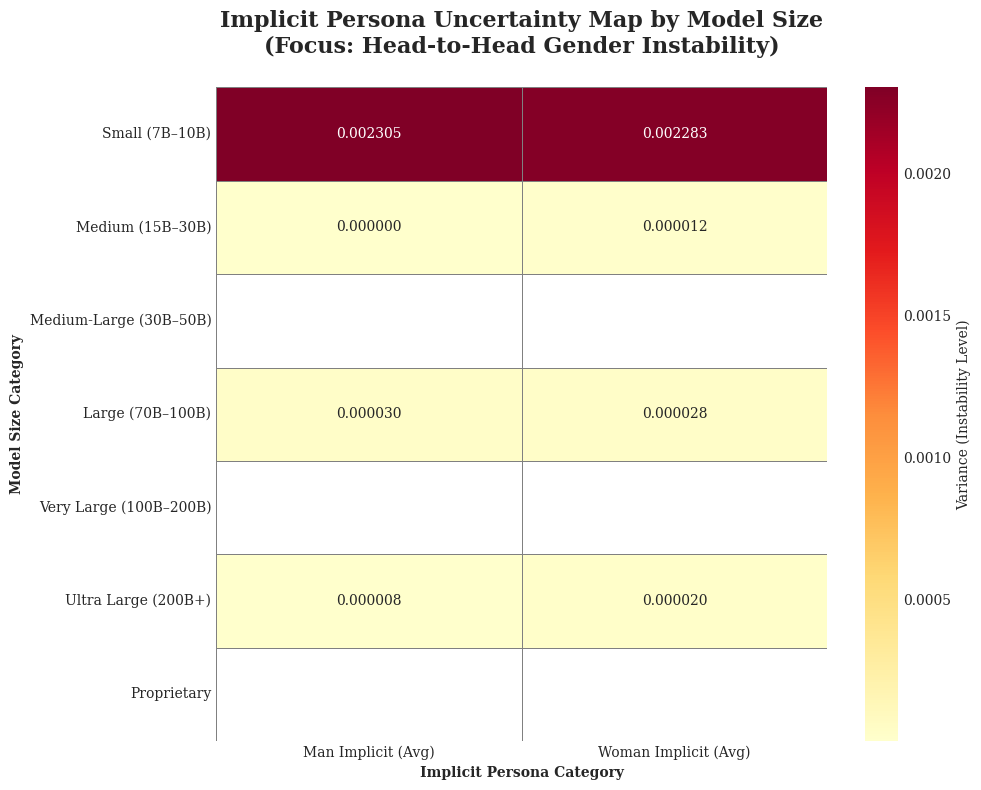

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Gunakan data mentah agar perhitungan varians valid
df_heatmap_raw = df_full.copy()
df_heatmap_raw['Size_Category'] = df_heatmap_raw['Model'].map(size_cat_map)

# 2. Hitung Varians (Accuracy) per Size dan per Category
# .var() di sini menghitung seberapa tidak stabil sebaran jawaban di kelas tersebut
df_var_grouped = df_heatmap_raw.groupby(['Size_Category', 'Category'])['Accuracy'].var().reset_index()

# 3. Filter: HANYA Implicit (Tanpa Neutral)
# Ini akan membuat perbandingan antar gender tersirat jadi lebih kontras
implicit_only = ['Man Implicit (Avg)', 'Woman Implicit (Avg)']
df_var_filtered = df_var_grouped[df_var_grouped['Category'].isin(implicit_only)]

# 4. Pivot & Reindex (Agar urutan ukuran model dari kecil ke besar)
pivot_var_size = df_var_filtered.pivot(index='Size_Category', columns='Category', values='Accuracy')
pivot_var_size = pivot_var_size.reindex(size_order)

# 5. Visualisasi Heatmap
plt.figure(figsize=(10, 8), dpi=100)
plt.rcParams['font.family'] = 'serif'

# Menggunakan YlOrRd: Semakin merah, semakin tinggi ketidakpastian/instabilitasnya
sns.heatmap(pivot_var_size,
            annot=True,
            cmap='YlOrRd',
            fmt='.6f',
            linewidths=0.5,
            linecolor='gray',
            cbar_kws={'label': 'Variance (Instability Level)'})

plt.title('Implicit Persona Uncertainty Map by Model Size\n(Focus: Head-to-Head Gender Instability)',
          fontsize=16, fontweight='bold', pad=25)
plt.ylabel('Model Size Category', fontweight='bold')
plt.xlabel('Implicit Persona Category', fontweight='bold')

plt.tight_layout()
plt.show()